<a href="https://colab.research.google.com/github/TERE4V4LOS/Analis-del-delito-Semanal/blob/main/Delitos_Serie_de_Tiempo_semanal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
drive.mount("/content/drive", force_remount=True)

IntSlider(value=0)

Widget: IntSlider(value=0)


In [1]:
#!pip install jupyter_bokeh
#!pip install geopandas
#!pip install panel
#!pip install --upgrade panel
#!pip install dbfread
#!pip install --upgrade panel bokeh
#!pip install -U panel bokeh
#!pip install -U panel bokeh jupyter_bokeh
import pandas as pd
import os
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# --- Configuración Inicial ---
ruta_carpeta = "data/delitos/csv"
df_resultados = None

# --- Lista de Delitos ---
lista_delitos = [
    'ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA', 'ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA',
    'HOMICIDIO CULPOSO POR ARMA DE FUEGO', 'ROBO A CASA HABITACION SIN VIOLENCIA', 'ROBO A NEGOCIO CON VIOLENCIA',
    'ROBO DE VEHICULO DE SERVICIO PARTICULAR CON VIOLENCIA', 'ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA',
    'ROBO A TRANSEUNTE DE CELULAR CON VIOLENCIA', 'ROBO A NEGOCIO SIN VIOLENCIA', 'ROBO DE ACCESORIOS DE AUTO',
    'HOMICIDIO POR ARMA DE FUEGO', 'ROBO A REPARTIDOR Y VEHICULO CON VIOLENCIA', 'ROBO A CASA HABITACION CON VIOLENCIA',
    'ROBO DE VEHICULO DE SERVICIO PÚBLICO SIN VIOLENCIA', 'ROBO DE VEHICULO DE PEDALES', 'HOMICIDIO POR ARMA BLANCA',
    'ROBO DE OBJETOS DEL INTERIOR DE UN VEHICULO', 'ROBO A TRANSEUNTE DE CELULAR SIN VIOLENCIA', 'HOMICIDIO POR GOLPES',
    'ROBO A REPARTIDOR SIN VIOLENCIA', 'ROBO DE VEHICULO DE SERVICIO PÚBLICO CON VIOLENCIA', 'ROBO DE MOTOCICLETA CON VIOLENCIA',
    'ROBO A REPARTIDOR CON VIOLENCIA', 'ROBO DE MOTOCICLETA SIN VIOLENCIA', 'ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOLENCIA',
    'NARCOMENUDEO POSESION SIMPLE', 'ROBO A CASA HABITACION Y VEHICULO SIN VIOLENCIA', 'DELITOS AMBIENTALES',
    'ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA', 'ROBO A PASAJERO A BORDO DE METROBUS SIN VIOLENCIA',
    'ROBO A TRANSEUNTE EN VIA PUBLICA SIN VIOLENCIA', 'ROBO DE VEHICULO DE SERVICIO DE TRANSPORTE SIN VIOLENCIA',
    'NARCOMENUDEO POSESIÓN CON FINES DE VENTA,COMERCIO Y SUMINISTRO', 'ROBO A NEGOCIO Y VEHICULO CON VIOLENCIA',
    'ROBO A TRANSEUNTE EN PARQUES Y MERCADOS CON VIOLENCIA', 'PORTACION DE ARMA DE FUEGO', 'ROBO A TRANSEUNTE EN NEGOCIO CON VIOLENCIA',
    'ROBO A TRANSPORTISTA Y VEHICULO PESADO CON VIOLENCIA', 'FEMINICIDIO', 'HOMICIDIO CULPOSO POR INSTRUMENTO PUNZO CORTANTE',
    'ROBO A SUCURSAL BANCARIA (ASALTO BANCARIO) CON VIOLENCIA', 'ROBO A PASAJERO A BORDO DE METROBUS CON VIOLENCIA',
    'ROBO DE VEHICULO DE SERVICIO DE TRANSPORTE CON VIOLENCIA', 'ROBO A CASA HABITACION Y VEHICULO CON VIOLENCIA',
    'ROBO A REPARTIDOR Y VEHICULO SIN VIOLENCIA', 'SECUESTRO EXPRESS (PARA COMETER ROBO O EXTORSIÓN)',
    'ROBO A NEGOCIO Y VEHICULO SIN VIOLENCIA', 'CONTAMINACIÓN O RESIDUOS', 'ROBO A TRANSPORTISTA Y VEHICULO PESADO SIN VIOLENCIA',
    'ROBO A SUCURSAL BANCARIA (SUPERMERCADO) SIN VIOLENCIA', 'ROBO A SUCURSAL BANCARIA (SUPERMERCADO) CON VIOLENCIA',
    'TALA', 'DELITOS CONTRA LA SALUD', 'ROBO A TRANSEUNTE Y VEHICULO CON VIOLENCIA', 'PLAGIO O SECUESTRO',
    'DESAPARICION FORZADA DE PERSONAS', 'PRIV. ILEGAL DE LA LIB. Y ROBO DE VEHICULO'
]
lista_delitos.sort()

# --- Configuración de Widgets (Nativos de Colab) ---
seleccion_delitos = widgets.SelectMultiple(
    options=lista_delitos,
    description='Delitos:',
    layout=widgets.Layout(width='80%', height='250px'),
    style={'description_width': 'initial'}
)

boton_buscar = widgets.Button(
    description=' Buscar Delitos',
    button_style='primary',
    icon='search',
    layout=widgets.Layout(width='200px', margin='10px 0px 10px 0px')
)

output_area = widgets.Output()

# --- Lógica de Botón ---
def on_button_clicked(b):
    global df_resultados

    # 1. Mostrar mensaje de carga
    with output_area:
        clear_output()
        display(HTML("<h4 style='color: #d9534f;'>⏳ Trabajando... buscando en los archivos, por favor espere...</h4>"))

        seleccion = seleccion_delitos.value
        if not seleccion:
            clear_output()
            display(HTML("<h4>⚠️ Por favor, selecciona al menos un delito (usa Ctrl o Cmd).</h4>"))
            return

        if not os.path.exists(ruta_carpeta):
            clear_output()
            display(HTML(f"<h4>❌ Error: No se encuentra la ruta: {ruta_carpeta}</h4>"))
            return

        # 2. Carga de datos
        datos_filtrados = pd.DataFrame()
        for archivo in os.listdir(ruta_carpeta):
            if archivo.endswith(".csv"):
                ruta_archivo = os.path.join(ruta_carpeta, archivo)
                try:
                    datos = pd.read_csv(ruta_archivo, low_memory=False)
                    filtrado = datos[datos['delito'].isin(seleccion)]
                    datos_filtrados = pd.concat([datos_filtrados, filtrado], ignore_index=True)
                except Exception as e:
                    print(f"Error menor en archivo {archivo}: {e}")

        df_resultados = datos_filtrados

        # 3. Mostrar la palomita
        clear_output()
        if not df_resultados.empty:
            display(HTML(f"<div style='background-color: #dff0d8; padding: 15px; border-radius: 5px; border-left: 5px solid #3c763d;'>"
                         f"<h3 style='color: #3c763d; margin: 0;'>✅ ¡Éxito!</h3>"
                         f"<b>Se cargaron correctamente {len(df_resultados)} registros.</b> La variable <code>df_resultados</code> está lista para usarse.</div>"))
        else:
            display(HTML("<h4>❌ No se encontraron registros con esos delitos.</h4>"))

boton_buscar.on_click(on_button_clicked)

# --- Mostrar la Interfaz ---
display(HTML("<h3>1. Selecciona los delitos de interés y presiona Buscar</h3>"))
display(seleccion_delitos, boton_buscar, output_area)

SelectMultiple(description='Delitos:', layout=Layout(height='250px', width='80%'), options=('CONTAMINACIÓN O R…

Button(button_style='primary', description=' Buscar Delitos', icon='search', layout=Layout(margin='10px 0px 10…

Output()

In [3]:
if 'conteo_semanal' in locals() and not conteo_semanal.empty:
    # Opción 1: Total de barras/periodos semanales generados en la gráfica
    total_semanas = len(conteo_semanal)

    # Opción 2: Cálculo basado en los días transcurridos entre la primera y última fecha
    fecha_inicio = df_resultados_filtrado['fecha_hecho'].min()
    fecha_fin = df_resultados_filtrado['fecha_hecho'].max()
    dias_totales = (fecha_fin - fecha_inicio).days
    semanas_teoricas = dias_totales / 7

    print("=" * 50)
    print("RESUMEN DEL PERIODO ANALIZADO")
    print("=" * 50)
    print(f"• Fecha de inicio: {fecha_inicio.strftime('%d/%m/%Y')}")
    print(f"• Fecha de término: {fecha_fin.strftime('%d/%m/%Y')}")
    print(f"• Total de días transcurridos: {dias_totales} días")
    print(f"• Total de semanas en la serie: {total_semanas} semanas")
    print(f"• Promedio teórico: {semanas_teoricas:.2f} semanas de 7 días")
    print("=" * 50)
else:
    print("❌ Primero debes ejecutar la celda donde se genera 'conteo_semanal'.")

RESUMEN DEL PERIODO ANALIZADO
• Fecha de inicio: 01/01/2016
• Fecha de término: 21/06/2024
• Total de días transcurridos: 3094 días
• Total de semanas en la serie: 282 semanas
• Promedio teórico: 442.00 semanas de 7 días


In [2]:
import pandas as pd
import plotly.graph_objects as go

# ======================================================================================
# 1. RECALCULAR SIEMPRE DESDE LA SELECCIÓN ACTUAL ('df_resultados')
# ======================================================================================
# Se lee directamente df_resultados para garantizar que se actualice al cambiar de delito
if 'df_resultados' in globals() and globals()['df_resultados'] is not None and not globals()['df_resultados'].empty:
    df_base = globals()['df_resultados'].copy()
elif 'df_resultados_filtrado' in globals() and globals()['df_resultados_filtrado'] is not None and not globals()['df_resultados_filtrado'].empty:
    df_base = globals()['df_resultados_filtrado'].copy()
else:
    df_base = None

if df_base is not None and 'fecha_hecho' in df_base.columns:
    df_base['fecha_hecho'] = pd.to_datetime(df_base['fecha_hecho'], errors='coerce')
    f_inicio = pd.Timestamp('2016-01-01')
    f_fin = pd.Timestamp('2024-06-30')

    # Filtrado por el periodo estricto
    df_resultados_filtrado = df_base[
        (df_base['fecha_hecho'] >= f_inicio) & (df_base['fecha_hecho'] <= f_fin)
    ].copy()

    total_registros = len(df_resultados_filtrado)

    if not df_resultados_filtrado.empty:
        # Bloques de 7 días iniciando el 01/01/2016 (Día 01)
        df_resultados_filtrado['semana_idx'] = (df_resultados_filtrado['fecha_hecho'] - f_inicio).dt.days // 7
        df_resultados_filtrado['fecha_hecho'] = f_inicio + pd.to_timedelta(df_resultados_filtrado['semana_idx'] * 7, unit='D')

        # Reconstrucción limpia de conteo_semanal
        conteo_semanal = (
            df_resultados_filtrado.groupby(['semana_idx', 'fecha_hecho'])
            .size()
            .reset_index(name='cantidad')
        )

        # Formateo de fechas para el eje X en español
        meses_es = {
            'Jan': 'Ene', 'Feb': 'Feb', 'Mar': 'Mar', 'Apr': 'Abr', 'May': 'May', 'Jun': 'Jun',
            'Jul': 'Jul', 'Aug': 'Ago', 'Sep': 'Sep', 'Oct': 'Oct', 'Nov': 'Nov', 'Dec': 'Dic'
        }
        conteo_semanal['fecha_str'] = conteo_semanal['fecha_hecho'].dt.strftime('%d-%b-%Y')
        for eng, esp in meses_es.items():
            conteo_semanal['fecha_str'] = conteo_semanal['fecha_str'].str.replace(eng, esp)
    else:
        conteo_semanal = pd.DataFrame()
        total_registros = 0
else:
    conteo_semanal = pd.DataFrame()
    total_registros = 0

# ======================================================================================
# 2. GENERACIÓN DE LA GRÁFICA INTERACTIVA PLOTLY (BARRAS LIMPIAS)
# ======================================================================================
if not conteo_semanal.empty:

    fig = go.Figure()

    # A. Barras limpias (relleno blanco y contorno negro definido)
    fig.add_trace(go.Bar(
        x=conteo_semanal['fecha_str'],
        y=conteo_semanal['cantidad'],
        marker=dict(color='white', line=dict(color='black', width=1)),
        name='Delitos'
    ))

    # B. Posición dinámica de nodos sobre las barras
    max_val = conteo_semanal['cantidad'].max()
    offset = max_val * 0.05 if max_val > 0 else 1

    # C. Nodos con numeración interna
    fig.add_trace(go.Scatter(
        x=conteo_semanal['fecha_str'],
        y=conteo_semanal['cantidad'] + offset,
        mode='markers+text',
        marker=dict(symbol='circle', color='white', size=14, line=dict(color='black', width=1)),
        text=[str(i) for i in range(len(conteo_semanal))],
        textfont=dict(color='black', size=8),
        textposition='middle center',
        name='Nodos'
    ))

    # D. Nombre dinámico del delito e intervalo de fechas
    if 'delito' in df_resultados_filtrado.columns and not df_resultados_filtrado['delito'].empty:
        nombre_delito = df_resultados_filtrado['delito'].iloc[0]
    else:
        nombre_delito = "Análisis de Incidencia"

    nombre_delito_formateado = str(nombre_delito).title()

    meses_traduccion = {
        'January': 'enero', 'February': 'febrero', 'March': 'marzo',
        'April': 'abril', 'May': 'mayo', 'June': 'junio',
        'July': 'julio', 'August': 'agosto', 'September': 'septiembre',
        'October': 'octubre', 'November': 'noviembre', 'December': 'diciembre'
    }

    fecha_min_dt = conteo_semanal['fecha_hecho'].min()
    fecha_max_dt = conteo_semanal['fecha_hecho'].max()
    mes_min_es = meses_traduccion.get(fecha_min_dt.strftime('%B'), fecha_min_dt.strftime('%B'))
    mes_max_es = meses_traduccion.get(fecha_max_dt.strftime('%B'), fecha_max_dt.strftime('%B'))

    titulo_dinamico = (
        f"Asignación de Nodos de la Serie Temporal Semanal de<br><b>{nombre_delito_formateado}</b><br>"
        f"<sub>({mes_min_es} {fecha_min_dt.year} – {mes_max_es} {fecha_max_dt.year})</sub>"
    )

    # E. Ajuste del diseño y visibilidad del eje horizontal
    etiquetas_visibles = conteo_semanal['fecha_str'][::16]

    fig.update_layout(
        title=dict(
            text=titulo_dinamico,
            x=0.5,
            xanchor='center',
            font=dict(size=16, color='black')
        ),
        width=1300, height=750,
        plot_bgcolor='white', paper_bgcolor='white',
        bargap=0.1,
        margin=dict(l=70, r=50, t=110, b=100),
        showlegend=False,
        xaxis=dict(
            title='Inicio de Semana (Bloques de 7 días desde 01/01/2016)',
            color='black', showline=True, linecolor='black', linewidth=1.5,
            tickangle=45, tickmode='array', tickvals=etiquetas_visibles
        ),
        yaxis=dict(
            title='Cantidad de delitos', color='black', showline=True, linecolor='black', linewidth=1.5,
            showgrid=True, gridcolor='lightgrey', gridwidth=0.2, griddash='dash',
            range=[0, max_val + (offset * 3)]
        )
    )

    fig.show()

    # ======================================================================================
    # 3. RESUMEN DE REGISTROS PROCESADOS
    # ======================================================================================
    print("=" * 65)
    print("RESUMEN DE DATOS DEL PERIODO ANALIZADO")
    print("=" * 65)
    print(f"• Delito actual: {nombre_delito_formateado}")
    print(f"• Total de registros analizados (filtrados): {total_registros:,}")
    print(f"• Rango de fechas: 01/01/2016 al 30/06/2024")
    print(f"• Total de semanas generadas (Nodos): {len(conteo_semanal)}")
    print("=" * 65)

else:
    print("❌ No se encontraron datos para el delito seleccionado dentro del periodo 01/01/2016 al 30/06/2024.")

RESUMEN DE DATOS DEL PERIODO ANALIZADO
• Delito actual: Robo A Transeunte Saliendo Del Cajero Con Violencia
• Total de registros analizados (filtrados): 634
• Rango de fechas: 01/01/2016 al 30/06/2024
• Total de semanas generadas (Nodos): 282


In [4]:
import pandas as pd
from IPython.display import display, HTML

# Este código asume que la variable 'conteo_semanal' ya existe.

if 'conteo_semanal' in locals() and not conteo_semanal.empty:

    # 1. Crear el DataFrame.
    tabla_nodos = pd.DataFrame({
        'Número de Nodo': range(len(conteo_semanal)),
        'Semana y Año': conteo_semanal['fecha_str'],
        'Cantidad de Delitos': conteo_semanal['cantidad']
    })

    # 2. Convertir el DataFrame a una cadena de texto HTML.
    html_string = tabla_nodos.to_html(index=False, escape=False)

    # 3. Modificar los encabezados para que tengan texto en dos líneas.
    html_string = html_string.replace('<th>Número de Nodo</th>', '<th>Número<br>de Nodo</th>')
    html_string = html_string.replace('<th>Semana y Año</th>', '<th>Semana y<br>Año</th>')
    html_string = html_string.replace('<th>Cantidad de Delitos</th>', '<th>Cantidad<br>de Delitos</th>')

    # --- 4. AÑADIR ESTILOS CSS CON ANCHOS DE COLUMNA ESPECÍFICOS ---
    styled_html = f"""
    <style>
        .tabla_compacta {{
            border-collapse: collapse;
            width: auto; /* Permite que el contenido defina el ancho */
            min-width: 350px; /* Ancho mínimo para evitar que el texto se junte */
            font-family: Arial, sans-serif;
            border: 1px solid #ccc;
        }}
        .tabla_compacta th, .tabla_compacta td {{
            border: 1px solid #ddd;
            text-align: left;
            padding: 8px;
        }}
        .tabla_compacta th {{
            background-color: #f2f2f2;
            text-align: center;
        }}
        /* --- Control de Ancho de Columna --- */
        .tabla_compacta th:nth-child(1), .tabla_compacta td:nth-child(1) {{ width: 25%; }} /* Columna 1: Número de Nodo */
        .tabla_compacta th:nth-child(2), .tabla_compacta td:nth-child(2) {{ width: 40%; }} /* Columna 2: Semana y Año */
        .tabla_compacta th:nth-child(3), .tabla_compacta td:nth-child(3) {{ width: 35%; }} /* Columna 3: Cantidad */
    </style>
    {html_string.replace('<table border="1" class="dataframe">', '<table class="tabla_compacta">')}
    """

    # 5. Mostrar la tabla HTML final con los estilos aplicados.
    print("Correspondencia de Nodos, Semana y Cantidad de Delitos:")
    display(HTML(styled_html))

else:
    print("❌ Error: No se encontraron datos procesados ('conteo_semanal') para generar la tabla.")
    print("Por favor, ejecute primero la celda que prepara los datos para el gráfico semanal.")

Correspondencia de Nodos, Semana y Cantidad de Delitos:


Númerode Nodo,Semana yAño,Cantidadde Delitos
0,01-Ene-2016,2
1,08-Ene-2016,2
2,15-Ene-2016,1
3,05-Feb-2016,2
4,12-Feb-2016,1
5,26-Feb-2016,1
6,04-Mar-2016,2
7,11-Mar-2016,2
8,25-Mar-2016,2
9,08-Abr-2016,1


In [5]:
# Ordena el DataFrame por 'cantidad' en orden descendente y selecciona las primeras 10 semanas
top_10_semanal = conteo_semanal.sort_values(
    by='cantidad', ascending=False
).head(10)

print("Las 10 semanas con mayor cantidad de delitos:")
display(top_10_semanal)

Las 10 semanas con mayor cantidad de delitos:


,semana_idx,fecha_hecho,cantidad,fecha_str
94,191,2019-08-30,7,30-Ago-2019
56,152,2018-11-30,7,30-Nov-2018
64,160,2019-01-25,6,25-Ene-2019
80,177,2019-05-24,6,24-May-2019
58,154,2018-12-14,6,14-Dic-2018
74,171,2019-04-12,6,12-Abr-2019
152,261,2021-01-01,6,01-Ene-2021
72,169,2019-03-29,5,29-Mar-2019
36,49,2016-12-09,5,09-Dic-2016
259,412,2023-11-24,5,24-Nov-2023


C:\Users\user\AppData\Local\Temp\ipykernel_18096\4184362620.py:10: RuntimeWarning: The 'origin' keyword does not take effect when resampling with a 'freq' that is not Tick-like (h, m, s, ms, us, ns)
  return df.resample('7D', on='fecha_hecho', origin='start').size().reset_index(name='cantidad')


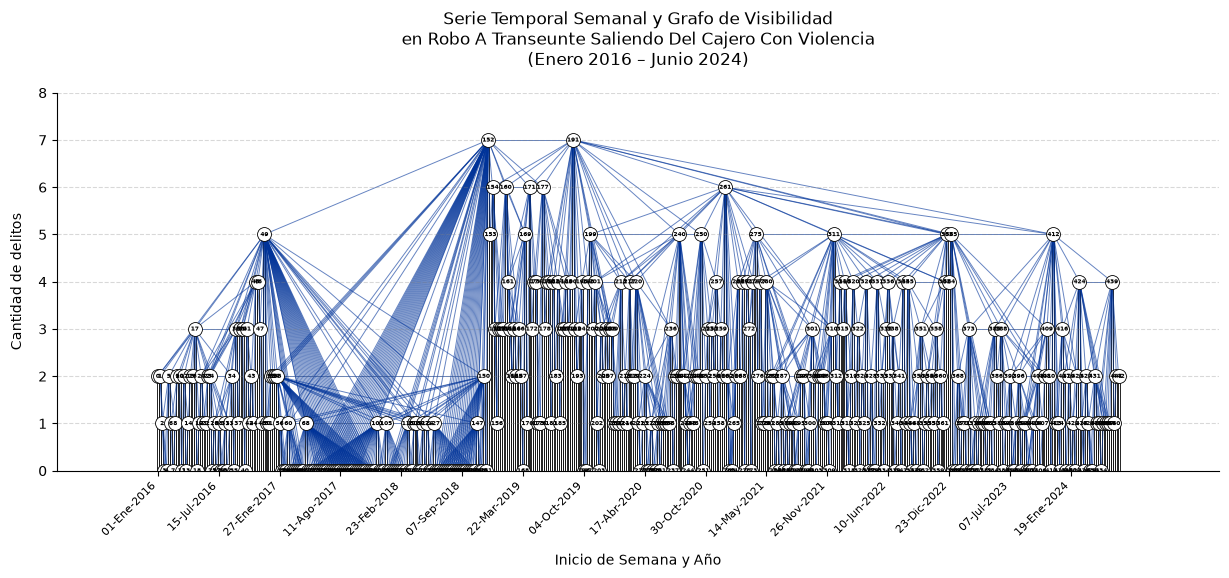

In [6]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import math

# --- 1. PROCESAMIENTO SEMANAL ---
def procesar_serie_semanal(df):
    # Agrupación en bloques de 7 días iniciando exactamente en el primer día disponible
    return df.resample('7D', on='fecha_hecho', origin='start').size().reset_index(name='cantidad')

def algoritmo_visibilidad_normal(valores):
    n = len(valores)
    G = nx.Graph()
    for i in range(n): G.add_node(i)
    for i in range(n):
        for j in range(i+1, n):
            visible = True
            for k in range(i+1, j):
                if valores[k] >= valores[j] + (valores[i] - valores[j]) * ((j - k) / (j - i)):
                    visible = False
                    break
            if visible: G.add_edge(i, j)
    return G

# --- 2. BLOQUE PRINCIPAL ---
if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
    serie_semanal = procesar_serie_semanal(df_resultados_filtrado)
    fechas = serie_semanal['fecha_hecho'].to_numpy(dtype='datetime64[ns]')
    valores = serie_semanal['cantidad'].to_numpy()

    if len(valores) >= 2:
        grafo = algoritmo_visibilidad_normal(valores)
        x = np.arange(len(valores))
        pos = {i: (x[i], valores[i]) for i in range(len(valores))}

        # Figura adaptada a la mayor densidad de la serie semanal
        fig, ax = plt.subplots(figsize=(15, 6), dpi=100)
        fig.patch.set_facecolor('white')

        # --- A. BARRAS SEMANALES ---
        ax.bar(x, valores, width=0.9, color='white', edgecolor='black',
               linewidth=0.6, alpha=1.0, label='Incidencia')

        # --- B. GRAFO OPTIMIZADO PARA ESCALA SEMANAL ---
        # Líneas de visibilidad
        nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color='#003399',
                               width=0.7, alpha=0.6)

        # Nodos y números ajustados para no saturar con ~400+ semanas
        nx.draw_networkx_nodes(grafo, pos, ax=ax, node_size=100, node_color="white",
                               edgecolors="black", linewidths=0.6)

        nx.draw_networkx_labels(grafo, pos, ax=ax, font_size=4.5, font_family='sans-serif',
                                font_weight='bold', font_color="black")

        # --- C. CONFIGURACIÓN DE EJES ---
        ax.set_axis_on()
        ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
        ax.set_xlabel("Inicio de Semana y Año", fontsize=10, color='black', labelpad=10)
        ax.set_ylabel("Cantidad de delitos", fontsize=10, color='black', labelpad=10)

        # Margen vertical superior
        ymax = np.max(valores)
        ax.set_ylim(0, ymax + max(1, int(ymax * 0.08)))

        # --- D. TÍTULO DINÁMICO ---
        meses_full_es = {
            'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
            'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
            'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
        }

        if 'delito' in locals() and delito:
            nombre_delito = delito
        elif 'delito' in df_resultados_filtrado.columns:
            nombre_delito = df_resultados_filtrado['delito'].iloc[0]
        else:
            nombre_delito = "Análisis de Incidencia"

        f_min, f_max = pd.Timestamp(fechas.min()), pd.Timestamp(fechas.max())
        periodo_txt = f"({meses_full_es.get(f_min.strftime('%B'))} {f_min.year} – {meses_full_es.get(f_max.strftime('%B'))} {f_max.year})"

        ax.set_title(f"Serie Temporal Semanal y Grafo de Visibilidad\nen {nombre_delito.title()}\n{periodo_txt}",
                     fontsize=12, pad=20, fontweight='normal', color='black')

        # --- E. ETIQUETADO DEL EJE X ---
        meses_abrev_es = {'Jan':'Ene','Feb':'Feb','Mar':'Mar','Apr':'Abr','May':'May','Jun':'Jun',
                          'Jul':'Jul','Aug':'Ago','Sep':'Sep','Oct':'Oct','Nov':'Nov','Dec':'Dic'}

        etiquetas_x = [f"{pd.Timestamp(d).strftime('%d')}-{meses_abrev_es.get(pd.Timestamp(d).strftime('%b'))}-{pd.Timestamp(d).year}" for d in fechas]

        # Salto de etiquetas ajustado a 16 semanas para mantener legible la gráfica
        step = max(1, math.ceil(len(x) / 16))
        ax.set_xticks(x[::step])
        ax.set_xticklabels(etiquetas_x[::step], rotation=45, ha='right', fontsize=8)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.yaxis.grid(True, linestyle='--', alpha=0.3, color='gray')

        plt.subplots_adjust(bottom=0.22, top=0.85)
        plt.show()

In [7]:
import networkx as nx
import pandas as pd

if 'grafo' in locals() and isinstance(grafo, nx.Graph):
    # --- Diccionario de traducción y atributos de nodos ---
    meses_traduccion = {
        'Jan': 'Ene', 'Feb': 'Feb', 'Mar': 'Mar', 'Apr': 'Abr', 'May': 'May', 'Jun': 'Jun',
        'Jul': 'Jul', 'Aug': 'Ago', 'Sep': 'Sep', 'Oct': 'Oct', 'Nov': 'Nov', 'Dec': 'Dic'
    }
    fechas_nodos = nx.get_node_attributes(grafo, 'fecha')

    def obtener_fecha_nodo(nodo):
        """Función auxiliar para obtener la fecha semanal formateada (Día-Mes-Año) de un nodo."""
        fecha_dt = fechas_nodos.get(nodo)
        if fecha_dt:
            # Asegurar que fecha_dt sea un objeto Timestamp
            if not isinstance(fecha_dt, pd.Timestamp):
                fecha_dt = pd.Timestamp(fecha_dt)

            fecha_str_ingles = fecha_dt.strftime('%d-%b-%Y')
            dia, mes_ingles, anio = fecha_str_ingles.split('-')
            mes_espanol = meses_traduccion.get(mes_ingles, mes_ingles)
            return f"{dia}-{mes_espanol}-{anio}"
        return "N/A"

    # Obtener el grado de cada nodo
    grados = dict(grafo.degree())

    # Crear un DataFrame para mostrar la información de manera organizada
    datos_nodos = []
    for nodo_id in sorted(grafo.nodes()):
        fecha_representada = obtener_fecha_nodo(nodo_id)
        grado_nodo = grados.get(nodo_id, 0)
        datos_nodos.append({
            'Número de Nodo': nodo_id,
            'Semana y Año': fecha_representada,
            'Grado (Conexiones)': grado_nodo
        })

    df_nodos_info = pd.DataFrame(datos_nodos)

    print("Información detallada de los vértices (nodos) del grafo de visibilidad semanal:")
    display(df_nodos_info)

else:
    print("❌ Error: No se encontró el objeto 'grafo'. Por favor, asegúrese de ejecutar la celda que crea el grafo primero.")

Información detallada de los vértices (nodos) del grafo de visibilidad semanal:


,Número de Nodo,Semana y Año,Grado (Conexiones)
0,0,N/A,3
1,1,N/A,5
2,2,N/A,4
3,3,N/A,3
4,4,N/A,4
...,...,...,...
438,438,N/A,4
439,439,N/A,13
440,440,N/A,2
441,441,N/A,3


Analizando el periodo filtrado...


C:\Users\user\AppData\Local\Temp\ipykernel_18096\36826360.py:17: RuntimeWarning: The 'origin' keyword does not take effect when resampling with a 'freq' that is not Tick-like (h, m, s, ms, us, ns)
  return df_filtrado.resample('7D', on='fecha_hecho', origin='start').size().reset_index(name='cantidad')


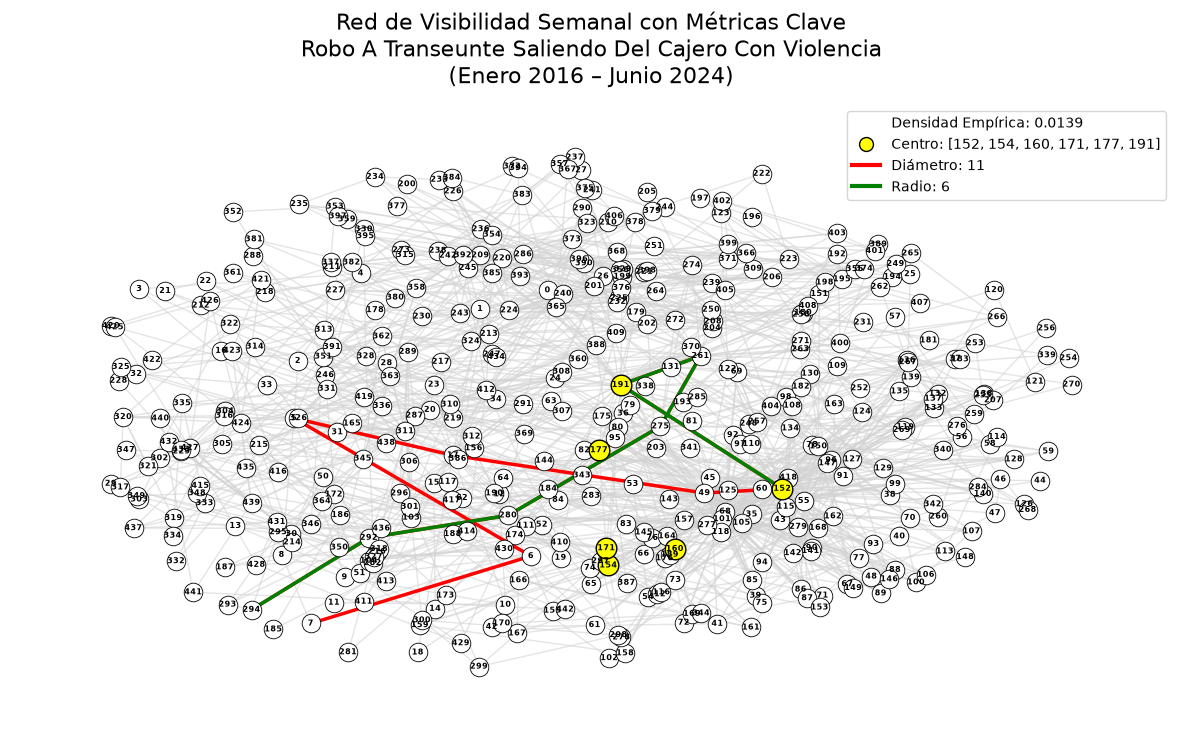


📊 **Métricas de la Red de Visibilidad Semanal**
- Número total de nodos (n): 443
- Número total de enlaces (m): 1356
- Densidad empírica (p): 0.0139
- Radio de la red: 6
- Diámetro de la red: 11
- Centro de la red (nodos): [152, 154, 160, 171, 177, 191]


In [8]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

#----------------------------------------------------------------------------------------
# F U N C I O N E S
#----------------------------------------------------------------------------------------

def procesar_serie_semanal(df):
    """Agrupa los datos por semanas de 7 días y cuenta los delitos."""
    df = df.copy()
    df['fecha_hecho'] = pd.to_datetime(df['fecha_hecho'], errors='coerce')
    df_filtrado = df[df['fecha_hecho'].dt.year >= 2016].copy()
    # Resample de 7 días iniciando exactamente en el primer registro disponible
    return df_filtrado.resample('7D', on='fecha_hecho', origin='start').size().reset_index(name='cantidad')

def algoritmo_visibilidad_normal(fechas, valores):
    """Implementa el algoritmo de visibilidad normal para crear el grafo."""
    n = len(valores)
    G = nx.Graph()
    fechas_num = np.array([fecha.timestamp() for fecha in fechas])
    for i in range(n):
        G.add_node(i, fecha=fechas[i], valor=valores[i])

    for i in range(n):
        for j in range(i + 1, n):
            visible = True
            for k in range(i + 1, j):
                if valores[k] >= valores[i] + (valores[j] - valores[i]) * \
                               ((fechas_num[k] - fechas_num[i]) / (fechas_num[j] - fechas_num[i])):
                    visible = False
                    break
            if visible:
                G.add_edge(i, j)
    return G

#----------------------------------------------------------------------------------------
# B L O Q U E   D E   E J E C U C I Ó N   P R I N C I P A L
#----------------------------------------------------------------------------------------

if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
    df_para_analisis = df_resultados_filtrado
    print("Analizando el periodo filtrado...")
elif 'df_resultados' in locals() and not df_resultados.empty:
    df_para_analisis = df_resultados
    print("Analizando el DataFrame completo...")
else:
    df_para_analisis = None
    print("❌ Error: No se encontraron datos para analizar.")

if df_para_analisis is not None:
    # 1. Preparar los datos semanales y crear el grafo.
    df_procesado = procesar_serie_semanal(df_para_analisis)
    grafo = algoritmo_visibilidad_normal(df_procesado['fecha_hecho'], df_procesado['cantidad'])

    # 2. Calcular las métricas.
    densidad_empirica = nx.density(grafo)

    radio, diametro, centro = None, None, None
    aristas_diametro, aristas_radio = [], []

    if nx.is_connected(grafo):
        radio = nx.radius(grafo)
        diametro = nx.diameter(grafo)
        centro = nx.center(grafo)

        try:
            path_lengths = dict(nx.shortest_path_length(grafo))
            n1_diam, n2_diam = None, None
            for u in grafo.nodes():
                for v in grafo.nodes():
                    if path_lengths[u][v] == diametro:
                        n1_diam, n2_diam = u, v
                        break
                if n1_diam: break

            if n1_diam is not None:
                camino_diametro_nodos = nx.shortest_path(grafo, source=n1_diam, target=n2_diam)
                aristas_diametro = list(zip(camino_diametro_nodos, camino_diametro_nodos[1:]))

            if centro:
                nodo_centro = centro[0]
                for target_node in grafo.nodes():
                    if path_lengths[nodo_centro][target_node] == radio:
                        camino_radio_nodos = nx.shortest_path(grafo, source=nodo_centro, target=target_node)
                        aristas_radio = list(zip(camino_radio_nodos, camino_radio_nodos[1:]))
                        break
        except Exception as e:
            print(f"Advertencia: No se pudo resaltar diámetro/radio. Error: {e}")
    else:
        print("El grafo no es conexo.")

    # --- 3. CONSTRUCCIÓN DEL TÍTULO DINÁMICO ---
    meses_es = {
        'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
        'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
        'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
    }

    if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
        nombre_delito = df_resultados_filtrado['delito'].iloc[0].title()
    elif 'df_resultados' in locals() and df_resultados is not None and not df_resultados.empty:
        nombre_delito = df_resultados['delito'].iloc[0].title()
    else:
        nombre_delito = "Delito Analizado"

    f_min_dt = df_procesado['fecha_hecho'].min()
    f_max_dt = df_procesado['fecha_hecho'].max()
    mes_min = meses_es.get(f_min_dt.strftime('%B'), f_min_dt.strftime('%B'))
    mes_max = meses_es.get(f_max_dt.strftime('%B'), f_max_dt.strftime('%B'))

    rango_fechas = f"({mes_min} {f_min_dt.year} – {mes_max} {f_max_dt.year})"
    titulo_grafico = f"Red de Visibilidad Semanal con Métricas Clave\n{nombre_delito}\n{rango_fechas}"

    # 4. Visualización ajustada a la escala semanal.
    fig, ax = plt.subplots(figsize=(15, 8))
    pos = nx.spring_layout(grafo, k=0.4, iterations=50, seed=42)

    # Capas de dibujo (tamaños de nodos y fuentes adaptados a la mayor cantidad de datos)
    nx.draw_networkx_edges(grafo, pos, edge_color='lightgray', width=1.0, alpha=0.6, ax=ax)
    nx.draw_networkx_nodes(grafo, pos, node_color='white', node_size=180, edgecolors='black', linewidths=0.6, ax=ax)

    if aristas_diametro:
        nx.draw_networkx_edges(grafo, pos, edgelist=aristas_diametro, edge_color='red', width=2.5, ax=ax)
    if aristas_radio:
        nx.draw_networkx_edges(grafo, pos, edgelist=aristas_radio, edge_color='green', width=2.5, ax=ax)
    if centro:
        nx.draw_networkx_nodes(grafo, pos, nodelist=centro, node_color='yellow', node_size=220, edgecolors='black', ax=ax)

    nx.draw_networkx_labels(grafo, pos, font_size=5.5, font_weight='bold', ax=ax)

    # 5. Leyenda informativa
    elementos_leyenda = [
        Line2D([0], [0], color='w', label=f'Densidad Empírica: {densidad_empirica:.4f}')
    ]

    if centro:
        elementos_leyenda.append(Line2D([0], [0], marker='o', color='w', label=f'Centro: {centro}', markerfacecolor='yellow', markersize=10, markeredgecolor='black'))
    if diametro is not None:
        elementos_leyenda.append(Line2D([0], [0], color='red', lw=3, label=f'Diámetro: {diametro}'))
    if radio is not None:
        elementos_leyenda.append(Line2D([0], [0], color='green', lw=3, label=f'Radio: {radio}'))

    ax.legend(handles=elementos_leyenda, loc='best', facecolor='white', framealpha=0.8, fontsize=10)

    plt.title(titulo_grafico, fontsize=16, pad=15)
    plt.axis('off')
    plt.show()

    # 6. Imprimir métricas finales
    print("\n📊 **Métricas de la Red de Visibilidad Semanal**")
    print(f"- Número total de nodos (n): {grafo.number_of_nodes()}")
    print(f"- Número total de enlaces (m): {grafo.number_of_edges()}")
    print(f"- Densidad empírica (p): {densidad_empirica:.4f}")
    if radio is not None:
        print(f"- Radio de la red: {radio}")
        print(f"- Diámetro de la red: {diametro}")
        print(f"- Centro de la red (nodos): {centro}")

In [9]:
import pandas as pd
import networkx as nx

# Se asume que el objeto 'grafo' ya existe de la celda de análisis semanal.
if 'grafo' in locals() and isinstance(grafo, nx.Graph):

    print("======================================================")
    print("      CÁLCULO DE MÉTRICAS (RED VISIBILIDAD SEMANAL)   ")
    print("======================================================")

    # --- Diccionario de traducción y atributos ---
    meses_traduccion = {
        'Jan': 'Ene', 'Feb': 'Feb', 'Mar': 'Mar', 'Apr': 'Abr', 'May': 'May', 'Jun': 'Jun',
        'Jul': 'Jul', 'Aug': 'Ago', 'Sep': 'Sep', 'Oct': 'Oct', 'Nov': 'Nov', 'Dec': 'Dic'
    }
    fechas_nodos = nx.get_node_attributes(grafo, 'fecha')
    valores_nodos = nx.get_node_attributes(grafo, 'valor')

    def obtener_fecha_nodo(nodo):
        """Obtiene y formatea la fecha del inicio de semana para cada nodo (Día-Mes-Año)."""
        fecha_dt = fechas_nodos.get(nodo)
        if fecha_dt:
            if not isinstance(fecha_dt, pd.Timestamp):
                fecha_dt = pd.Timestamp(fecha_dt)
            fecha_str_ingles = fecha_dt.strftime('%d-%b-%Y')
            dia, mes_ingles, anio = fecha_str_ingles.split('-')
            mes_espanol = meses_traduccion.get(mes_ingles, mes_ingles)
            return f"{dia}-{mes_espanol}-{anio}"
        return "N/A"

    # --- 1. CÁLCULO DE MÉTRICAS GLOBALES ---
    grados = dict(grafo.degree())
    centralidad_intermediacion = nx.betweenness_centrality(grafo)
    centralidad_cercania = nx.closeness_centrality(grafo)
    agrupamiento = nx.clustering(grafo)

    # Excentricidad (solo si es conexo)
    if nx.is_connected(grafo):
        excentricidad = nx.eccentricity(grafo)
    else:
        excentricidad = {n: "N/A" for n in grafo.nodes()}

    # --- 2. CREACIÓN DEL DATAFRAME (TABLA COMPLETA) ---
    lista_metricas = []

    for nodo in sorted(grafo.nodes()):
        lista_metricas.append({
            'Nodo': nodo,
            'Inicio de Semana': obtener_fecha_nodo(nodo),
            'Frecuencia (Delitos)': valores_nodos.get(nodo, 0),
            'Grado (Conexiones)': grados.get(nodo),
            'Intermediación': round(centralidad_intermediacion.get(nodo, 0), 4),
            'Cercanía': round(centralidad_cercania.get(nodo, 0), 4),
            'Agrupamiento': round(agrupamiento.get(nodo, 0), 4),
            'Excentricidad': excentricidad.get(nodo)
        })

    # Crear el DataFrame
    df_metricas = pd.DataFrame(lista_metricas)

    # --- 3. MOSTRAR RESULTADOS ---
    pd.set_option('display.max_rows', None)  # Forzar a mostrar todas las filas
    print("\nTABLA COMPLETA DE MÉTRICAS POR NODO (SEMANAL):")
    display(df_metricas)

    # --- 4. EXPORTAR (Opcional) ---
    # df_metricas.to_csv("metricas_red_visibilidad_semanal.csv", index=False)

    # --- 5. RESUMEN DE DISTANCIAS ---
    if nx.is_connected(grafo):
        print("\n--- RESUMEN DE LA RED SEMANAL ---")
        print(f"- Diámetro: {nx.diameter(grafo)}")
        print(f"- Radio: {nx.radius(grafo)}")
        print(f"- Centro: {nx.center(grafo)}")

    print("\n======================================================")
    print("         Análisis de Nodos Semanal Finalizado         ")
    print("======================================================")

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal. Ejecuta primero la celda que construye el grafo.")

      CÁLCULO DE MÉTRICAS (RED VISIBILIDAD SEMANAL)   

TABLA COMPLETA DE MÉTRICAS POR NODO (SEMANAL):


,Nodo,Inicio de Semana,Frecuencia (Delitos),Grado (Conexiones),Intermediación,Cercanía,Agrupamiento,Excentricidad
0,0,01-Ene-2016,2,3,0.0048,0.2283,0.6667,8
1,1,08-Ene-2016,2,5,0.0058,0.1898,0.5000,9
2,2,15-Ene-2016,1,4,0.0000,0.1600,0.8333,10
3,3,22-Ene-2016,0,3,0.0000,0.1599,1.0000,10
4,4,29-Ene-2016,0,4,0.0000,0.1600,0.8333,10
5,5,05-Feb-2016,2,8,0.0143,0.1901,0.3571,9
6,6,12-Feb-2016,1,4,0.0023,0.1601,0.6667,10
7,7,19-Feb-2016,0,2,0.0000,0.1381,1.0000,11
8,8,26-Feb-2016,1,4,0.0023,0.1601,0.6667,10
9,9,04-Mar-2016,2,5,0.0067,0.1899,0.5000,9



--- RESUMEN DE LA RED SEMANAL ---
- Diámetro: 11
- Radio: 6
- Centro: [152, 154, 160, 171, 177, 191]

         Análisis de Nodos Semanal Finalizado         


In [10]:
import pandas as pd
import networkx as nx

# ======================================================================================
# CÁLCULO Y VISUALIZACIÓN DE MÉTRICAS COMPLETAS DE LA RED (ANÁLISIS SEMANAL)
# ======================================================================================

# Se asume que el objeto 'grafo' ya existe de la celda de análisis semanal.
if 'grafo' in locals() and isinstance(grafo, nx.Graph):

    print("======================================================")
    print("   RESUMEN DE MÉTRICAS DE LA RED DE VISIBILIDAD SEMANAL ")
    print("======================================================")

    # --- Diccionario de traducción y atributos de nodos ---
    meses_traduccion = {
        'Jan': 'Ene', 'Feb': 'Feb', 'Mar': 'Mar', 'Apr': 'Abr', 'May': 'May', 'Jun': 'Jun',
        'Jul': 'Jul', 'Aug': 'Ago', 'Sep': 'Sep', 'Oct': 'Oct', 'Nov': 'Nov', 'Dec': 'Dic'
    }
    fechas_nodos = nx.get_node_attributes(grafo, 'fecha')

    def obtener_fecha_nodo(nodo):
        """Función auxiliar para obtener la fecha de inicio de semana formateada (Día-Mes-Año)."""
        fecha_dt = fechas_nodos.get(nodo)
        if fecha_dt:
            if not isinstance(fecha_dt, pd.Timestamp):
                fecha_dt = pd.Timestamp(fecha_dt)
            fecha_str_ingles = fecha_dt.strftime('%d-%b-%Y')
            dia, mes_ingles, anio = fecha_str_ingles.split('-')
            mes_espanol = meses_traduccion.get(mes_ingles, mes_ingles)
            return f"{dia}-{mes_espanol}-{anio}"
        return "N/A"

    # --- 1. MÉTRICAS GENERALES ---
    print("\n--- 1. MÉTRICAS GENERALES DE LA RED ---")
    num_nodos = grafo.number_of_nodes()
    num_enlaces = grafo.number_of_edges()
    componentes = nx.number_connected_components(grafo)

    print(f"- Número total de Nodos (Semanas): {num_nodos}")
    print(f"- Número total de Enlaces: {num_enlaces}")
    print(f"- Componentes Conectados: {componentes}")

    # --- 2. CÁLCULO DE MÉTRICAS GLOBALES DE NODOS ---
    print("\n--- 2. CÁLCULO DE MÉTRICAS GLOBALES DE NODOS ---")

    grados = dict(grafo.degree())
    centralidad_intermediacion = nx.betweenness_centrality(grafo)
    centralidad_cercania = nx.closeness_centrality(grafo)
    agrupamiento = nx.clustering(grafo)

    print("- Métricas de Grado, Intermediación, Cercanía y Agrupamiento calculadas.")

    # --- 3. MÉTRICAS DE DISTANCIA (Solo si el grafo es conexo) ---
    print("\n--- 3. MÉTRICAS DE DISTANCIA ---")
    if componentes == 1:
        diametro = nx.diameter(grafo)
        radio = nx.radius(grafo)
        centro = nx.center(grafo)
        excentricidad = nx.eccentricity(grafo)
        print(f"- Diámetro de la Red: {diametro}")
        print(f"- Radio de la Red: {radio}")
        print(f"- Centro de la Red (Nodos): {centro}")

        excentricidad_ordenada = sorted(excentricidad.items(), key=lambda item: item[1])
        print("\n  - TOP 5 Nodos con Menor Excentricidad (más céntricos):")
        for nodo, exc in excentricidad_ordenada[:5]:
            print(f"    - Nodo {nodo} (Semana {obtener_fecha_nodo(nodo)}): Excentricidad = {exc}")
    else:
        centro = []
        excentricidad = {}
        print("- El grafo no es conexo, no se pueden calcular Diámetro, Radio, Centro ni Excentricidad.")

    # --- 4. ANÁLISIS DE NODOS CLAVE ---
    print("\n--- 4. ANÁLISIS DE NODOS CLAVE ---")

    valores_nodos = nx.get_node_attributes(grafo, 'valor')

    if valores_nodos:
        nodo_mas_alto = max(valores_nodos, key=valores_nodos.get)
        valor_maximo = valores_nodos[nodo_mas_alto]
        print(f"\n  - Nodo Pico (Semana con Valor Máximo):")
        print(f"    - Nodo {nodo_mas_alto} (Inicio {obtener_fecha_nodo(nodo_mas_alto)}) con {valor_maximo} delitos")

        print(f"    - Métricas Específicas del Nodo Pico ({nodo_mas_alto}):")
        print(f"      - Grado (Conexiones): {grados.get(nodo_mas_alto, 'N/A')}")

        exc_pico = excentricidad.get(nodo_mas_alto)
        print(f"      - Excentricidad: {exc_pico if exc_pico is not None else 'N/A (No conexo)'}")
        print(f"      - Centralidad de Intermediación: {centralidad_intermediacion.get(nodo_mas_alto, 0):.4f}")
        print(f"      - Centralidad de Cercanía: {centralidad_cercania.get(nodo_mas_alto, 0):.4f}")
        print(f"      - Coeficiente de Agrupamiento: {agrupamiento.get(nodo_mas_alto, 0):.4f}")

    if centro:
        print(f"\n  - Métricas de los Nodos del Centro ({centro}):")
        for nodo_central in centro:
            print(f"    - Análisis del Nodo {nodo_central} (Semana {obtener_fecha_nodo(nodo_central)}):")
            print(f"      - Grado (Conexiones): {grados.get(nodo_central, 'N/A')}")
            print(f"      - Centralidad de Intermediación: {centralidad_intermediacion.get(nodo_central, 0):.4f}")
            print(f"      - Centralidad de Cercanía: {centralidad_cercania.get(nodo_central, 0):.4f}")
            print(f"      - Coeficiente de Agrupamiento: {agrupamiento.get(nodo_central, 0):.4f}")

    # --- 5. TOP 5 NODOS POR MÉTRICA ---
    print("\n--- 5. TOP 5 NODOS POR MÉTRICA ---")

    grados_ordenados = sorted(grados.items(), key=lambda item: item[1], reverse=True)
    print("\n  - TOP 5 Nodos con Mayor Grado (más conectados):")
    for nodo, grado in grados_ordenados[:5]:
        print(f"    - Nodo {nodo} ({obtener_fecha_nodo(nodo)}): {grado} conexiones")

    intermediacion_ordenada = sorted(centralidad_intermediacion.items(), key=lambda item: item[1], reverse=True)
    print("\n  - TOP 5 Nodos con Mayor Centralidad de Intermediación (puentes):")
    for nodo, centralidad in intermediacion_ordenada[:5]:
        print(f"    - Nodo {nodo} ({obtener_fecha_nodo(nodo)}): {centralidad:.4f}")

    cercania_ordenada = sorted(centralidad_cercania.items(), key=lambda item: item[1], reverse=True)
    print("\n  - TOP 5 Nodos con Mayor Centralidad de Cercanía (mejor acceso):")
    for nodo, centralidad in cercania_ordenada[:5]:
        print(f"    - Nodo {nodo} ({obtener_fecha_nodo(nodo)}): {centralidad:.4f}")

    # --- 6. COEFICIENTE DE AGRUPAMIENTO (CLUSTERING) ---
    print("\n--- 6. COEFICIENTE DE AGRUPAMIENTO (CLUSTERING) ---")

    agrupamiento_ordenado = sorted(agrupamiento.items(), key=lambda item: item[1], reverse=True)

    print("\n  - Nodos con Mayor Coeficiente (en grupos más densos):")
    for nodo, coef in agrupamiento_ordenado[:5]:
        print(f"    - Nodo {nodo} ({obtener_fecha_nodo(nodo)}): {coef:.4f}")

    print("\n  - Nodos con Menor Coeficiente (en grupos menos densos):")
    nodos_menor_agrupamiento = [item for item in reversed(agrupamiento_ordenado) if item[1] > 0][:5]
    if not nodos_menor_agrupamiento:
        nodos_menor_agrupamiento = list(reversed(agrupamiento_ordenado[-5:]))

    for nodo, coef in nodos_menor_agrupamiento:
        print(f"    - Nodo {nodo} ({obtener_fecha_nodo(nodo)}): {coef:.4f}")

    print("\n======================================================")
    print("      Análisis de Métricas Semanales Finalizado        ")
    print("======================================================")

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal en la memoria.")
    print("Por favor, asegúrese de ejecutar primero la celda que crea el grafo con resample semanal.")

   RESUMEN DE MÉTRICAS DE LA RED DE VISIBILIDAD SEMANAL 

--- 1. MÉTRICAS GENERALES DE LA RED ---
- Número total de Nodos (Semanas): 443
- Número total de Enlaces: 1356
- Componentes Conectados: 1

--- 2. CÁLCULO DE MÉTRICAS GLOBALES DE NODOS ---
- Métricas de Grado, Intermediación, Cercanía y Agrupamiento calculadas.

--- 3. MÉTRICAS DE DISTANCIA ---
- Diámetro de la Red: 11
- Radio de la Red: 6
- Centro de la Red (Nodos): [152, 154, 160, 171, 177, 191]

  - TOP 5 Nodos con Menor Excentricidad (más céntricos):
    - Nodo 152 (Semana 30-Nov-2018): Excentricidad = 6
    - Nodo 154 (Semana 14-Dic-2018): Excentricidad = 6
    - Nodo 160 (Semana 25-Ene-2019): Excentricidad = 6
    - Nodo 171 (Semana 12-Abr-2019): Excentricidad = 6
    - Nodo 177 (Semana 24-May-2019): Excentricidad = 6

--- 4. ANÁLISIS DE NODOS CLAVE ---

  - Nodo Pico (Semana con Valor Máximo):
    - Nodo 152 (Inicio 30-Nov-2018) con 7 delitos
    - Métricas Específicas del Nodo Pico (152):
      - Grado (Conexiones): 74
 

Calculando la distribución de grados de la red de visibilidad semanal...


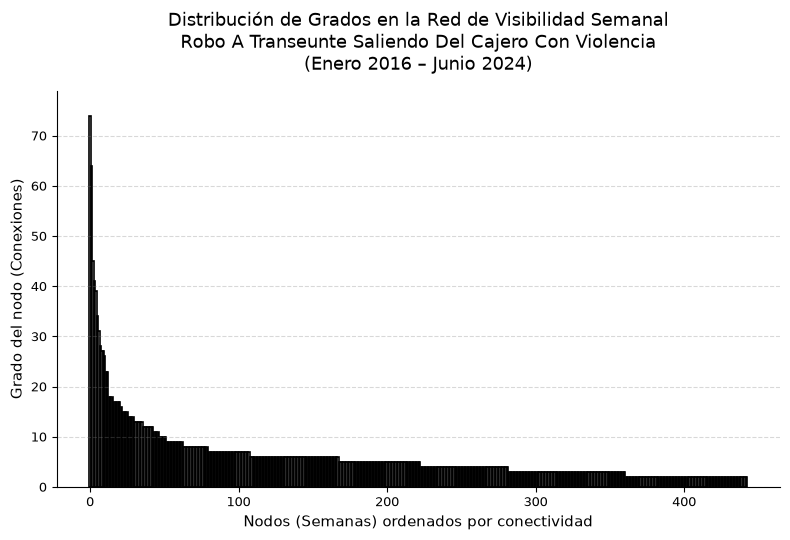

In [11]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Este bloque depende de que el objeto 'grafo' exista de la celda de análisis semanal.
if 'grafo' in locals() and isinstance(grafo, nx.Graph):
    print("Calculando la distribución de grados de la red de visibilidad semanal...")

    # 1. Obtener los grados de todos los nodos.
    grados = dict(grafo.degree())

    if not grados:
        print("⚠️ El grafo no tiene nodos, no se puede generar la distribución de grados.")
    else:
        # 2. Ordenar los grados de mayor a menor.
        grados_ordenados = sorted(grados.values(), reverse=True)

        # --- INICIO DE LA CREACIÓN DEL GRÁFICO ---

        # 3. Crear la figura
        fig, ax = plt.subplots(figsize=(8, 5.5), dpi=100)
        fig.patch.set_facecolor('white')
        ax.patch.set_facecolor('white')

        # 4. Dibujar el gráfico de barras.
        x_pos = np.arange(len(grados_ordenados))
        ax.bar(x_pos, grados_ordenados, color='white', edgecolor='black', linewidth=1.2)

        # --- 5. TÍTULO DINÁMICO SEMANAL DIVIDIDO EN LÍNEAS ---
        if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
            delito_nombre = df_resultados_filtrado['delito'].iloc[0].title()
        elif 'df_resultados' in locals() and df_resultados is not None and not df_resultados.empty:
            delito_nombre = df_resultados['delito'].iloc[0].title()
        else:
            delito_nombre = "Delito Analizado"

        # Extraer rango de fechas directamente de las propiedades del grafo
        fechas_nodos = nx.get_node_attributes(grafo, 'fecha')
        if fechas_nodos:
            meses_es = {
                'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
                'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
                'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
            }
            f_min = min(fechas_nodos.values())
            f_max = max(fechas_nodos.values())
            if not isinstance(f_min, pd.Timestamp): f_min = pd.Timestamp(f_min)
            if not isinstance(f_max, pd.Timestamp): f_max = pd.Timestamp(f_max)
            mes_min = meses_es.get(f_min.strftime('%B'), f_min.strftime('%B'))
            mes_max = meses_es.get(f_max.strftime('%B'), f_max.strftime('%B'))
            linea2 = f"({mes_min} {f_min.year} – {mes_max} {f_max.year})"
        elif 'rango_titulo' in locals():
            linea2 = rango_titulo
        else:
            linea2 = "(Distribución Semanal de Conectividad)"

        linea1 = f"Distribución de Grados en la Red de Visibilidad Semanal\n{delito_nombre}"

        ax.set_title(f"{linea1}\n{linea2}", fontsize=13, pad=15, color='black', fontweight='normal')

        # 6. Etiquetas y estilo
        ax.set_ylabel("Grado del nodo (Conexiones)", fontsize=11, color='black')
        ax.set_xlabel("Nodos (Semanas) ordenados por conectividad", fontsize=11, color='black')

        # --- AJUSTE DE ALTURA DE BARRAS ---
        gmax = max(grados_ordenados)
        ax.set_ylim(0, gmax + max(1, int(gmax * 0.08)))

        # 7. Limpieza estética
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('black')
        ax.spines['bottom'].set_color('black')

        # 8. Marcas de los ejes
        ax.tick_params(axis='both', direction='out', colors='black', labelsize=9)
        ax.yaxis.grid(True, linestyle='--', alpha=0.3, color='gray')

        # 9. Ajustar el layout
        plt.tight_layout()
        plt.show()

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal. Asegúrate de ejecutar primero la celda que genera el grafo.")

<>:82: SyntaxWarning: invalid escape sequence '\g'
<>:82: SyntaxWarning: invalid escape sequence '\g'
C:\Users\user\AppData\Local\Temp\ipykernel_18096\74065569.py:82: SyntaxWarning: invalid escape sequence '\g'
  f"Gamma ($\gamma$): {fit.power_law.alpha:.4f}\n"


Calculando ajuste de Ley de Potencia para la red de visibilidad semanal...
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 26/26 [00:00<00:00, 265.23it/s]
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


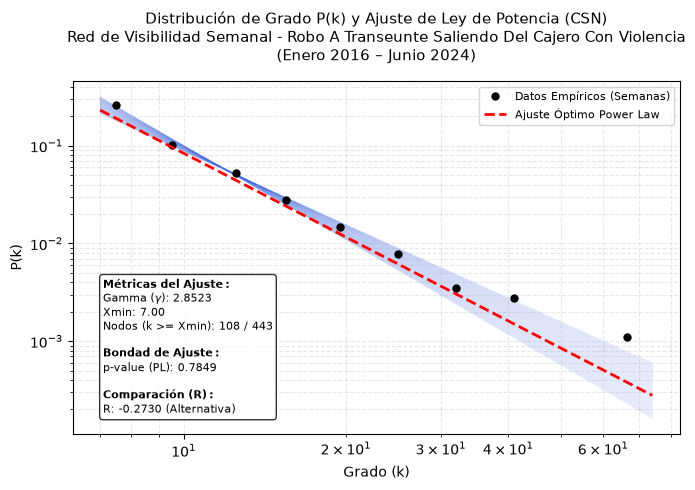

In [12]:
#!pip install powerlaw
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import powerlaw
import numpy as np

# Se asume que el objeto 'grafo' proviene del análisis semanal.
if 'grafo' in locals() and isinstance(grafo, nx.Graph):
    print("Calculando ajuste de Ley de Potencia para la red de visibilidad semanal...")

    # 1. PREPARACIÓN DE DATOS (Secuencia de grados > 0)
    degree_sequence = [d for n, d in grafo.degree() if d > 0]
    data = np.array(degree_sequence)

    if len(data) == 0:
        print("⚠️ El grafo no tiene nodos con grado mayor a cero.")
    else:
        fit = powerlaw.Fit(data, discrete=True)

        # 2. COMPARACIONES Y ESTADÍSTICAS
        R, p_value_PL = fit.distribution_compare('power_law', 'lognormal', normalized_ratio=True)
        res_log = "Power Law" if R > 0 else "Alternativa"
        sigma_val = fit.power_law.sigma
        xmin_val = fit.power_law.xmin
        nodos_cumplen = np.sum(data >= xmin_val)
        total_nodos = len(data)

        # --- 3. TÍTULO DINÁMICO SEMANAL ---
        if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
            nombre_delito = df_resultados_filtrado['delito'].iloc[0].title()
        elif 'df_resultados' in locals() and df_resultados is not None and not df_resultados.empty:
            nombre_delito = df_resultados['delito'].iloc[0].title()
        elif 'delito' in locals():
            nombre_delito = str(delito).title()
        else:
            nombre_delito = "Delito Analizado"

        # Extraer rango de fechas directamente del atributo 'fecha' de los nodos
        fechas_nodos = nx.get_node_attributes(grafo, 'fecha')
        if fechas_nodos:
            meses_es = {
                'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
                'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
                'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
            }
            f_min = min(fechas_nodos.values())
            f_max = max(fechas_nodos.values())
            if not isinstance(f_min, pd.Timestamp): f_min = pd.Timestamp(f_min)
            if not isinstance(f_max, pd.Timestamp): f_max = pd.Timestamp(f_max)
            mes_min = meses_es.get(f_min.strftime('%B'), f_min.strftime('%B'))
            mes_max = meses_es.get(f_max.strftime('%B'), f_max.strftime('%B'))
            linea_fechas = f"({mes_min} {f_min.year} – {mes_max} {f_max.year})"
        elif 'rango_titulo' in locals():
            linea_fechas = rango_titulo
        else:
            linea_fechas = "(Análisis Semanal)"

        titulo_grafico = (
            f"Distribución de Grado P(k) y Ajuste de Ley de Potencia (CSN)\n"
            f"Red de Visibilidad Semanal - {nombre_delito}\n"
            f"{linea_fechas}"
        )

        # 4. GENERACIÓN DEL GRÁFICO (Tamaño 7x5)
        plt.figure(figsize=(7, 5), dpi=100)

        # Bandas de Confianza
        x_space = np.linspace(xmin_val, data.max(), 100)
        for s in np.linspace(-2, 2, 50):
            gamma_var = fit.power_law.alpha + (s * sigma_val)
            y_var = (gamma_var - 1) * (xmin_val**(gamma_var - 1)) * (x_space**-gamma_var)
            plt.plot(x_space, y_var, color='royalblue', alpha=0.15, linewidth=0.6, zorder=1)

        # Datos empíricos y Ajuste óptimo
        fit.plot_pdf(color='black', marker='o', linestyle='None', markersize=5, label='Datos Empíricos (Semanas)')
        fit.power_law.plot_pdf(color='red', linestyle='--', linewidth=2, label='Ajuste Óptimo Power Law')

        # 5. CUADRO DE ANOTACIONES
        texto_stats = (
            f"$\\mathbf{{Métricas\\ del\\ Ajuste:}}$\n"
            f"Gamma ($\gamma$): {fit.power_law.alpha:.4f}\n"
            f"Xmin: {xmin_val:.2f}\n"
            f"Nodos (k >= Xmin): {int(nodos_cumplen)} / {total_nodos}\n\n"
            f"$\\mathbf{{Bondad\\ de\\ Ajuste:}}$\n"
            f"p-value (PL): {p_value_PL:.4f}\n\n"
            f"$\\mathbf{{Comparación\\ (R):}}$\n"
            f"R: {R:.4f} ({res_log})"
        )
        plt.text(0.05, 0.05, texto_stats, transform=plt.gca().transAxes, fontsize=8,
                 verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

        plt.title(titulo_grafico, fontsize=11, pad=15)
        plt.xlabel('Grado (k)', fontsize=10)
        plt.ylabel('P(k)', fontsize=10)
        plt.xscale('log')
        plt.yscale('log')
        plt.grid(True, which="both", ls="--", alpha=0.3)
        plt.legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.show()

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal en la memoria.")

Calculando ajustes y distancias euclidianas...
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 26/26 [00:00<00:00, 541.62it/s]


   DISTANCIA EUCLIDIANA RESPECTO A LOS DATOS EMPÍRICOS
         Modelo  Distancia Euclidiana
Ley de Potencia              0.073930
     Log-Normal              0.076269
    Exponencial              0.147152



c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


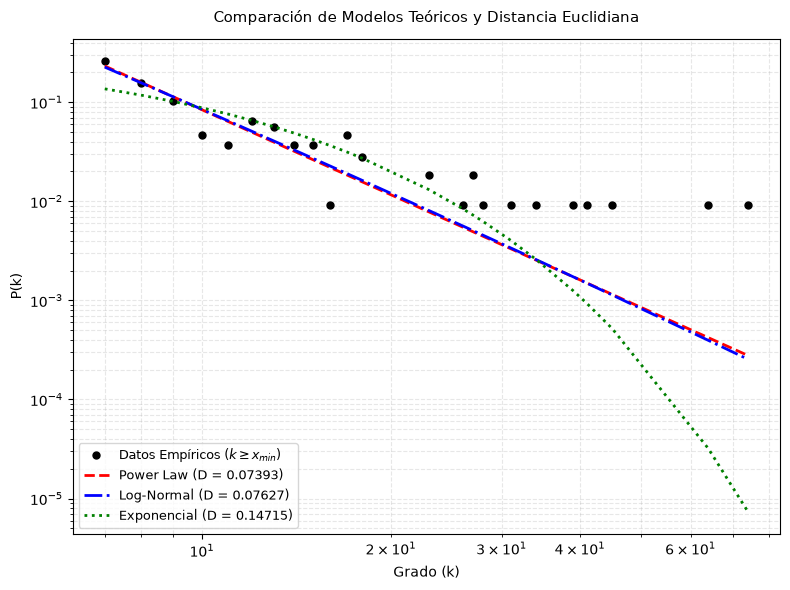

In [13]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import powerlaw

# Se asume que el objeto 'grafo' proviene del análisis semanal.
if 'grafo' in locals() and isinstance(grafo, nx.Graph):
    print("Calculando ajustes y distancias euclidianas...")

    # 1. PREPARACIÓN DE DATOS (Secuencia de grados > 0)
    degree_sequence = [d for n, d in grafo.degree() if d > 0]
    data = np.array(degree_sequence)

    if len(data) == 0:
        print("⚠️ El grafo no tiene nodos con grado mayor a cero.")
    else:
        # 2. AJUSTE MULTIMODELO (Power Law, Log-Normal, Exponential)
        fit = powerlaw.Fit(data, discrete=True)
        xmin_val = fit.xmin

        # 3. OBTENCIÓN EXACTA DE DATOS EMPÍRICOS (k >= xmin)
        data_xmin = data[data >= xmin_val]

        if len(data_xmin) == 0:
            print("⚠️ No hay suficientes datos por encima de xmin.")
        else:
            # Grados únicos y su probabilidad empírica real
            k_eval, counts = np.unique(data_xmin, return_counts=True)
            y_emp_eval = counts / len(data_xmin)  # Normalizado en la región k >= xmin

            # 4. EVALUACIÓN DE LAS DISTRIBUCIONES TEÓRICAS
            y_pl = fit.power_law.pdf(k_eval)
            y_lognorm = fit.lognormal.pdf(k_eval)
            y_exp = fit.exponential.pdf(k_eval)

            # 5. CÁLCULO DE LA DISTANCIA EUCLIDIANA
            dist_pl = np.linalg.norm(y_emp_eval - y_pl)
            dist_lognorm = np.linalg.norm(y_emp_eval - y_lognorm)
            dist_exp = np.linalg.norm(y_emp_eval - y_exp)

            # Crear DataFrame resumen
            df_distancias = pd.DataFrame({
                'Modelo': ['Ley de Potencia', 'Log-Normal', 'Exponencial'],
                'Distancia Euclidiana': [dist_pl, dist_lognorm, dist_exp]
            }).sort_values(by='Distancia Euclidiana').reset_index(drop=True)

            # Mostrar tabla en consola
            print("\n" + "="*50)
            print("   DISTANCIA EUCLIDIANA RESPECTO A LOS DATOS EMPÍRICOS")
            print("="*50)
            print(df_distancias.to_string(index=False))
            print("="*50)

            # --- 6. GRÁFICO COMPARATIVO DE MODELOS Y DISTANCIAS ---
            plt.figure(figsize=(8, 6), dpi=100)

            # CORRECCIÓN AQUÍ: '\geq' en lugar de '\ge'
            plt.plot(k_eval, y_emp_eval, 'ko', label='Datos Empíricos ($k \\geq x_{min}$)', markersize=5)

            # Curvas de ajuste
            plt.plot(k_eval, y_pl, 'r--', linewidth=2, label=f'Power Law (D = {dist_pl:.5f})')
            plt.plot(k_eval, y_lognorm, 'b-.', linewidth=2, label=f'Log-Normal (D = {dist_lognorm:.5f})')
            plt.plot(k_eval, y_exp, 'g:', linewidth=2, label=f'Exponencial (D = {dist_exp:.5f})')

            plt.xscale('log')
            plt.yscale('log')
            plt.xlabel('Grado (k)', fontsize=10)
            plt.ylabel('P(k)', fontsize=10)
            plt.title('Comparación de Modelos Teóricos y Distancia Euclidiana', fontsize=11, pad=12)
            plt.grid(True, which="both", ls="--", alpha=0.3)
            plt.legend(loc='lower left', fontsize=9)

            plt.tight_layout()
            plt.show()

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal en la memoria.")

Calculando análisis de Ley de Potencia (CSN) para la red semanal...
Calculating best minimal value for power law fit


Fitting xmin:   0%|          | 0/26 [00:00<?, ?it/s]

Fitting xmin: 100%|██████████| 26/26 [00:00<00:00, 360.96it/s]
c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


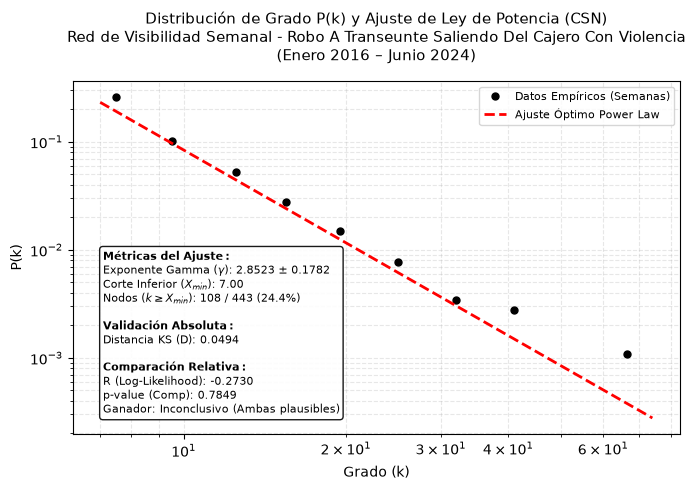

In [18]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import powerlaw
import numpy as np

# Se asume que el objeto 'grafo' proviene de la celda de análisis semanal.
if 'grafo' in locals() and isinstance(grafo, nx.Graph):
    print("Calculando análisis de Ley de Potencia (CSN) para la red semanal...")

    # ==========================================
    # 1. PREPARACIÓN DE DATOS Y AJUSTE CSN
    # ==========================================
    degree_sequence = [d for n, d in grafo.degree() if d > 0]
    data = np.array(degree_sequence)

    if len(data) == 0:
        print("⚠️ El grafo no tiene nodos con grado mayor a cero.")
    else:
        # Ajuste según la metodología CSN (2009) para datos discretos
        fit = powerlaw.Fit(data, discrete=True)

        # Distancia KS (D) para evaluar bondad de ajuste absoluta
        ks_distancia = fit.power_law.D

        # ==========================================
        # 2. COMPARACIONES Y ESTADÍSTICAS (MÉTODO CSN)
        # ==========================================
        # Comparamos Ley de Potencia vs Lognormal
        R_log, p_comp = fit.distribution_compare('power_law', 'lognormal', normalized_ratio=True)

        if p_comp < 0.05:
            res_log = "Power Law" if R_log > 0 else "Lognormal"
        else:
            res_log = "Inconclusivo (Ambas plausibles)"

        # Parámetros del ajuste
        gamma_val = fit.power_law.alpha
        sigma_val = fit.power_law.sigma
        xmin_val = fit.power_law.xmin
        nodos_cumplen = np.sum(data >= xmin_val)
        total_nodos = len(data)

        # ==========================================
        # 3. TÍTULO DINÁMICO SEMANAL
        # ==========================================
        if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
            nombre_delito = df_resultados_filtrado['delito'].iloc[0].title()
        elif 'df_resultados' in locals() and df_resultados is not None and not df_resultados.empty:
            nombre_delito = df_resultados['delito'].iloc[0].title()
        elif 'delito' in locals():
            nombre_delito = str(delito).title()
        else:
            nombre_delito = "Delito Analizado"

        # Formateo de fechas extraídas de los nodos del grafo semanal
        fechas_nodos = nx.get_node_attributes(grafo, 'fecha')
        if fechas_nodos:
            meses_es = {
                'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
                'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
                'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
            }
            f_min = min(fechas_nodos.values())
            f_max = max(fechas_nodos.values())
            if not isinstance(f_min, pd.Timestamp): f_min = pd.Timestamp(f_min)
            if not isinstance(f_max, pd.Timestamp): f_max = pd.Timestamp(f_max)
            mes_min = meses_es.get(f_min.strftime('%B'), f_min.strftime('%B'))
            mes_max = meses_es.get(f_max.strftime('%B'), f_max.strftime('%B'))
            linea_fechas = f"({mes_min} {f_min.year} – {mes_max} {f_max.year})"
        elif 'rango_titulo' in locals():
            linea_fechas = rango_titulo
        else:
            linea_fechas = "(Análisis Semanal)"

        titulo_grafico = (
            f"Distribución de Grado P(k) y Ajuste de Ley de Potencia (CSN)\n"
            f"Red de Visibilidad Semanal - {nombre_delito}\n"
            f"{linea_fechas}"
        )

        # ==========================================
        # 4. GENERACIÓN DEL GRÁFICO
        # ==========================================
        plt.figure(figsize=(7, 5), dpi=100)

        fit.plot_pdf(color='black', marker='o', linestyle='None', markersize=5, label='Datos Empíricos (Semanas)')
        fit.power_law.plot_pdf(color='red', linestyle='--', linewidth=2, label='Ajuste Óptimo Power Law')

        # ==========================================
        # 5. CUADRO DE ANOTACIONES
        # ==========================================
        texto_stats = (
            r"$\mathbf{Métricas\ del\ Ajuste:}$" + "\n"
            f"Exponente Gamma ($\\gamma$): {gamma_val:.4f} $\\pm$ {sigma_val:.4f}\n"
            f"Corte Inferior ($X_{{min}}$): {xmin_val:.2f}\n"
            f"Nodos ($k \\geq X_{{min}}$): {int(nodos_cumplen)} / {total_nodos} ({nodos_cumplen/total_nodos*100:.1f}%)\n\n"
            r"$\mathbf{Validación\ Absoluta:}$" + "\n"
            f"Distancia KS (D): {ks_distancia:.4f}\n\n"
            r"$\mathbf{Comparación\ Relativa:}$" + "\n"
            f"R (Log-Likelihood): {R_log:.4f}\n"
            f"p-value (Comp): {p_comp:.4f}\n"
            f"Ganador: {res_log}"
        )

        plt.text(0.05, 0.05, texto_stats, transform=plt.gca().transAxes, fontsize=8,
                 verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

        plt.title(titulo_grafico, fontsize=11, pad=15)
        plt.xlabel('Grado (k)', fontsize=10)
        plt.ylabel('P(k)', fontsize=10)
        plt.xscale('log')
        plt.yscale('log')
        plt.grid(True, which="both", ls="--", alpha=0.3)
        plt.legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.show()

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal en la memoria.")


--- Parámetros Estructurales Semanales para Robo A Transeunte Saliendo Del Cajero Con Violencia ---
           Métrica  Valor
   Nodos (Semanas)    443
       Enlaces (m)   1356
Grado Promedio (k) 6.1219
      Densidad (p) 0.0139
-------------------------------------------------------


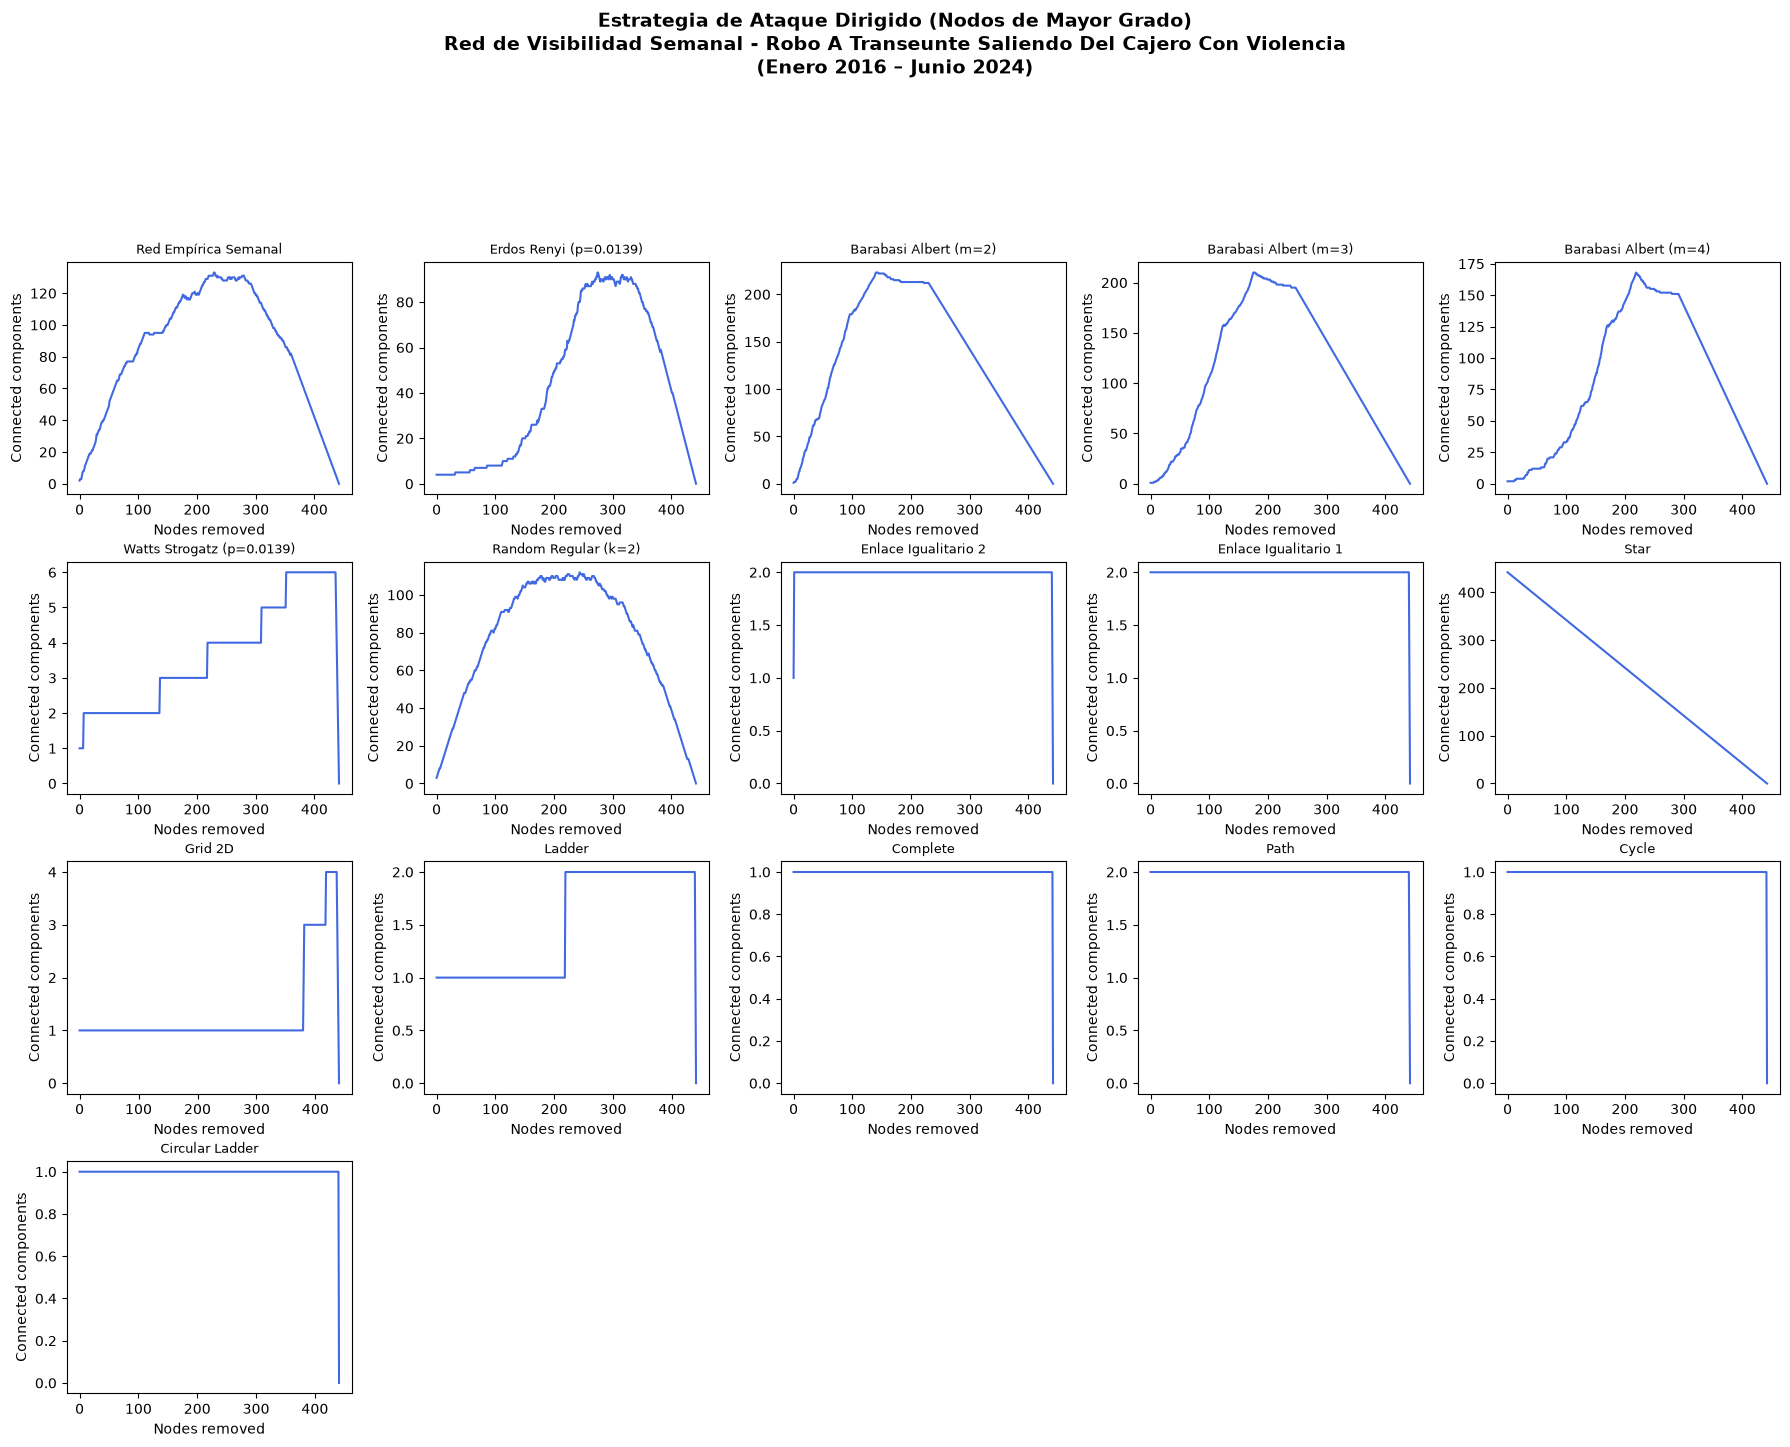


--- Parámetros Estructurales Semanales para Robo A Transeunte Saliendo Del Cajero Con Violencia ---
           Métrica  Valor
   Nodos (Semanas)    443
       Enlaces (m)   1356
Grado Promedio (k) 6.1219
      Densidad (p) 0.0139
-------------------------------------------------------


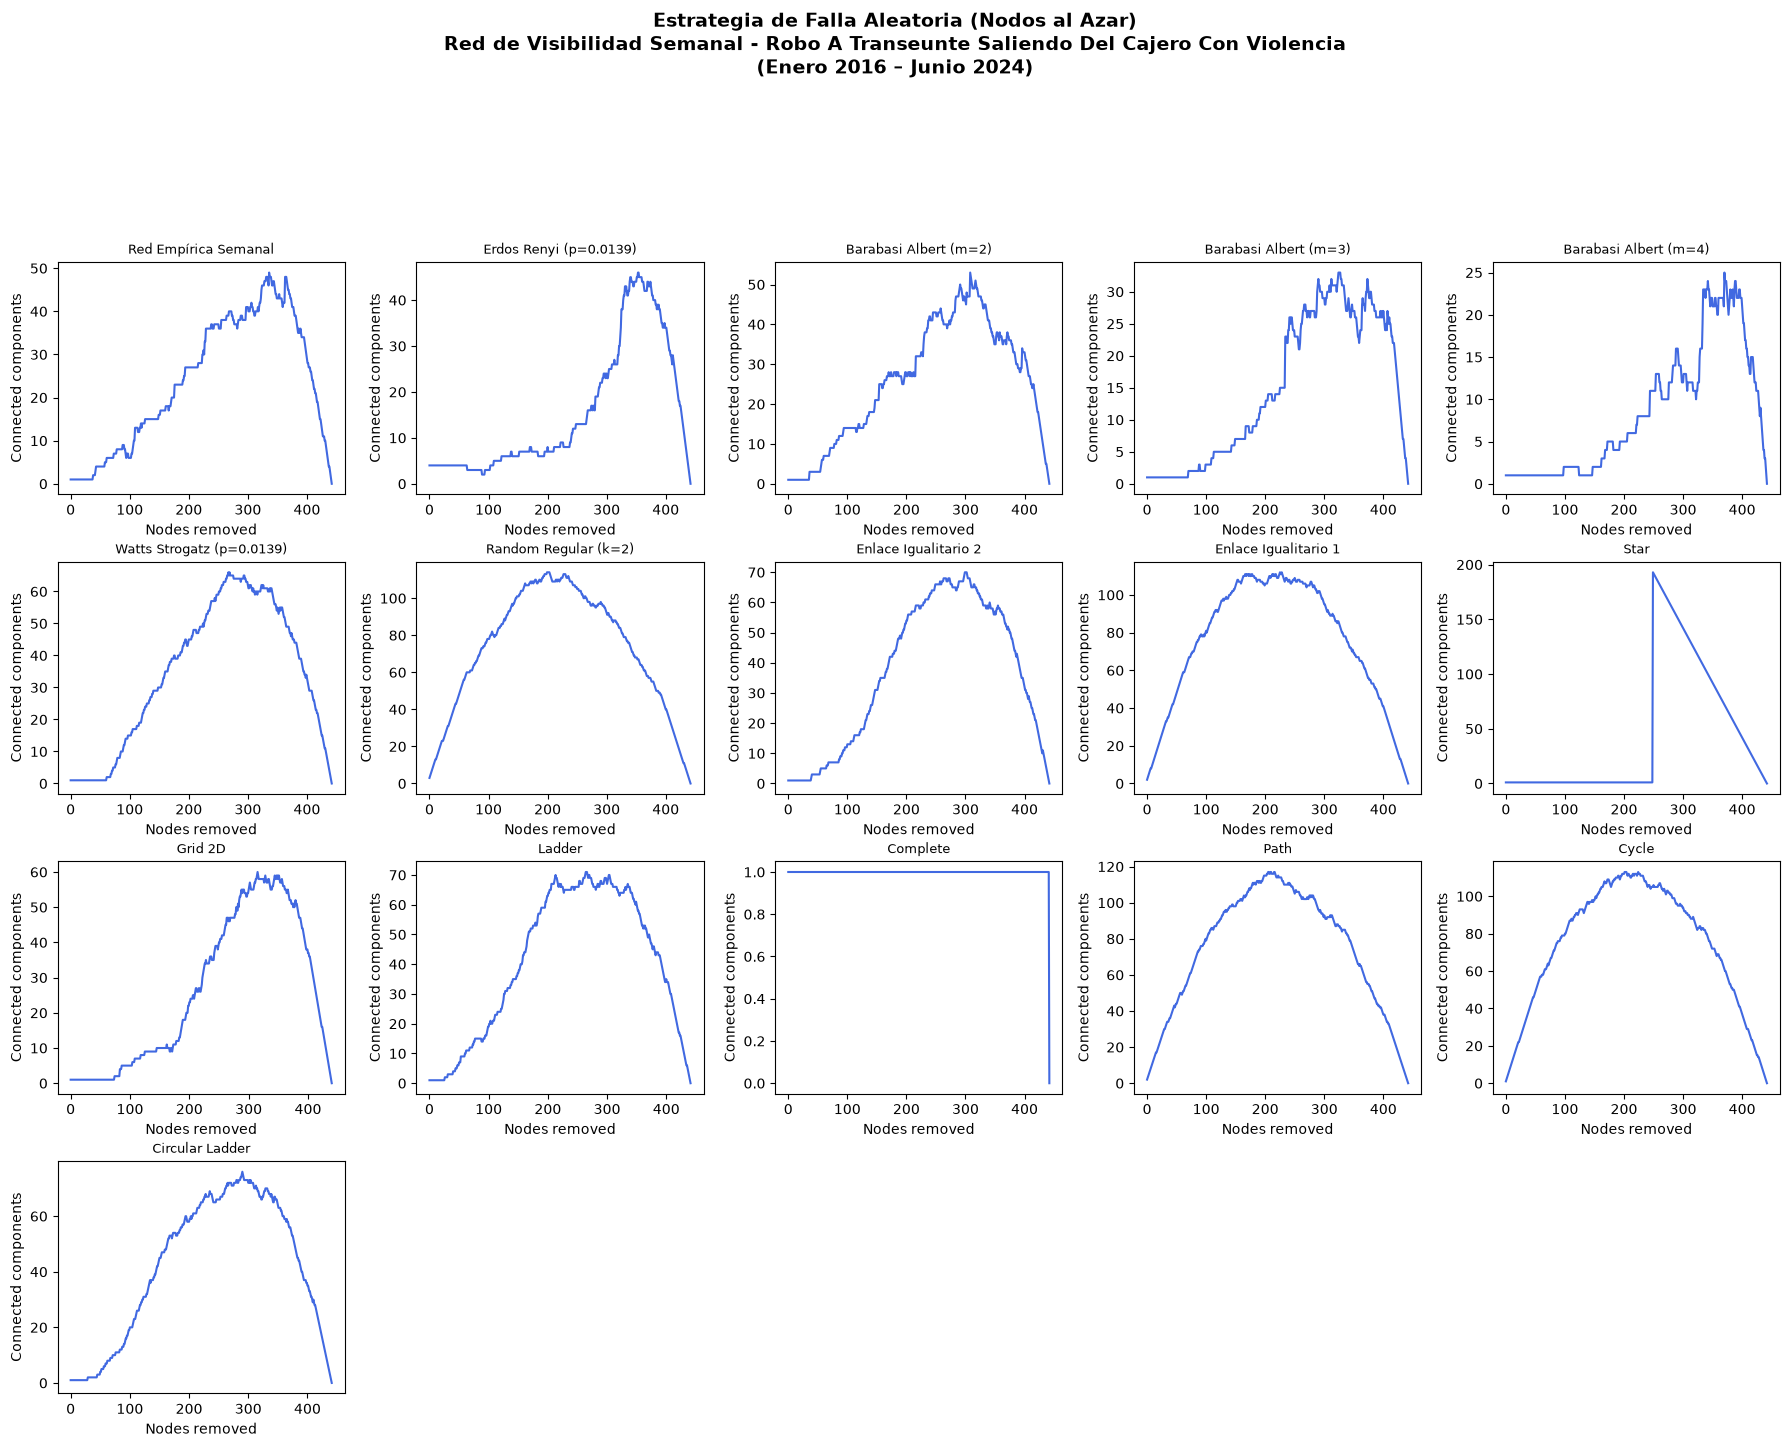

In [19]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from itertools import islice

# Verificación de existencia del grafo de análisis semanal
if 'grafo' in locals() and isinstance(grafo, nx.Graph):

    # ---------------------------------------------------------
    # 1. CÁLCULO DE PARÁMETROS DINÁMICOS (Red Real Semanal)
    # ---------------------------------------------------------
    n_empirico = grafo.number_of_nodes()
    m_empirico = grafo.number_of_edges()

    # p: Probabilidad de conexión (Densidad)
    p_empirico = (2 * m_empirico) / (n_empirico * (n_empirico - 1)) if n_empirico > 1 else 0

    # k: Grado promedio
    k_promedio = sum(dict(grafo.degree()).values()) / n_empirico if n_empirico > 0 else 0
    k_promedio_redondeado = int(round(k_promedio))

    # Parámetro m para Barabasi-Albert
    m_ba = max(1, k_promedio_redondeado // 2)

    # Raíz cuadrada para el modelo Grid
    sqrt_nodes = int(np.sqrt(n_empirico))

    # ---------------------------------------------------------
    # 2. CREACIÓN DE TABLA DE PARÁMETROS
    # ---------------------------------------------------------
    df_params = pd.DataFrame({
        'Métrica': ['Nodos (Semanas)', 'Enlaces (m)', 'Grado Promedio (k)', 'Densidad (p)'],
        'Valor': [n_empirico, m_empirico, f"{k_promedio:.4f}", f"{p_empirico:.4f}"]
    })

    # ---------------------------------------------------------
    # 3. CATÁLOGO COMPLETO DE 17 REDES (Dinámico)
    # ---------------------------------------------------------
    def rebuild_graphs(grafo_existente):
        num_nodes = grafo_existente.number_of_nodes()

        def enlace_igualitario(n, k):
            G = nx.Graph()
            G.add_nodes_from(range(n))
            for i in range(n):
                for j in range(i + 1, min(i + k + 1, n)):
                    G.add_edge(i, j)
            return G

        return {
            'Red Empírica Semanal': grafo_existente,
            f'Erdos Renyi (p={p_empirico:.4f})': nx.erdos_renyi_graph(num_nodes, p_empirico),
            'Barabasi Albert (m=2)': nx.barabasi_albert_graph(num_nodes, 2) if num_nodes > 2 else None,
            'Barabasi Albert (m=3)': nx.barabasi_albert_graph(num_nodes, 3) if num_nodes > 3 else None,
            'Barabasi Albert (m=4)': nx.barabasi_albert_graph(num_nodes, 4) if num_nodes > 4 else None,
            f'Watts Strogatz (p={p_empirico:.4f})': nx.watts_strogatz_graph(num_nodes, 4, p_empirico) if num_nodes >= 4 else None,
            'Random Regular (k=2)': nx.random_regular_graph(2, num_nodes) if num_nodes > 2 else None,
            'Enlace Igualitario 2': enlace_igualitario(num_nodes, 2),
            'Enlace Igualitario 1': enlace_igualitario(num_nodes, 1),
            'Star': nx.star_graph(num_nodes - 1) if num_nodes > 0 else None,
            'Grid 2D': nx.grid_2d_graph(sqrt_nodes, sqrt_nodes) if sqrt_nodes > 0 else None,
            'Ladder': nx.ladder_graph(num_nodes // 2) if num_nodes >= 2 else None,
            'Hypercube': nx.hypercube_graph(int(np.log2(num_nodes))) if (num_nodes > 0 and (num_nodes & (num_nodes - 1)) == 0) else None,
            'Complete': nx.complete_graph(num_nodes),
            'Path': nx.path_graph(num_nodes),
            'Cycle': nx.cycle_graph(num_nodes),
            'Circular Ladder': nx.circular_ladder_graph(num_nodes // 2) if num_nodes >= 2 else None,
        }

    # ---------------------------------------------------------
    # 4. FUNCIONES DE ORDENAMIENTO Y RENORMALIZACIÓN
    # ---------------------------------------------------------
    def nodes_higher_degree_first(G):
        return sorted(G.nodes(), key=lambda x: G.degree(x), reverse=True)

    def nodes_random(G):
        nodes = list(G.nodes())
        np.random.shuffle(nodes)
        return nodes

    def renorm_connected_components(G, nodes, ax):
        connected_components = []
        G_copy = G.copy()
        for node in nodes:
            if node in G_copy:
                G_copy.remove_node(node)
            connected_components.append(nx.number_connected_components(G_copy))
        ax.plot(connected_components, color='royalblue')
        ax.set_xlabel("Nodes removed")
        ax.set_ylabel("Connected components")

    def plot_renorm(feature, node_list_func, graphs):
        valid_graphs = {k: v for k, v in graphs.items() if v is not None}
        num_graphs = len(valid_graphs)
        rows = (num_graphs + 4) // 5
        fig, ax = plt.subplots(rows, 5, figsize=(18, 3.5 * rows))
        ax = ax.flatten()

        for i, (name, graph) in enumerate(valid_graphs.items()):
            ax[i].set_title(name, fontsize=9)
            feature(graph.copy(), node_list_func(graph.copy()), ax[i])

        for j in range(i + 1, len(ax)):
            ax[j].set_visible(False)

        plt.tight_layout()

    # ---------------------------------------------------------
    # 5. LÓGICA DE TÍTULO DINÁMICO Y TABLA (SEMANAL)
    # ---------------------------------------------------------
    def aplicar_formato_final(estrategia_nombre):
        # 1. Búsqueda dinámica del nombre del delito
        if 'df_resultados_filtrado' in globals() and not df_resultados_filtrado.empty:
            delito_fmt = df_resultados_filtrado['delito'].iloc[0].title()
        elif 'df_resultados' in globals() and globals()['df_resultados'] is not None and not df_resultados.empty:
            delito_fmt = df_resultados['delito'].iloc[0].title()
        elif 'delito' in globals():
            delito_fmt = str(delito).title()
        else:
            delito_fmt = "Delito Analizado"

        # 2. Búsqueda dinámica del rango de fechas desde las propiedades del grafo semanal
        fechas_nodos = nx.get_node_attributes(grafo, 'fecha')
        meses_es = {
            'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
            'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
            'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
        }

        if fechas_nodos:
            f_min = min(fechas_nodos.values())
            f_max = max(fechas_nodos.values())
            if not isinstance(f_min, pd.Timestamp): f_min = pd.Timestamp(f_min)
            if not isinstance(f_max, pd.Timestamp): f_max = pd.Timestamp(f_max)
            mes_min = meses_es.get(f_min.strftime('%B'), f_min.strftime('%B'))
            mes_max = meses_es.get(f_max.strftime('%B'), f_max.strftime('%B'))
            periodo_txt = f"({mes_min} {f_min.year} – {mes_max} {f_max.year})"
        elif 'rango_titulo' in globals():
            periodo_txt = rango_titulo
        else:
            periodo_txt = "(Análisis Semanal)"

        # 3. Aplicación de títulos al gráfico
        fig = plt.gcf()
        fig.suptitle(f"{estrategia_nombre}\nRed de Visibilidad Semanal - {delito_fmt}\n{periodo_txt}",
                     fontsize=14, y=1.03, fontweight='bold')
        plt.subplots_adjust(top=0.85)

        # 4. Mostrar la tabla de valores en consola para referencia
        print(f"\n--- Parámetros Estructurales Semanales para {delito_fmt} ---")
        if 'df_params' in globals():
            print(df_params.to_string(index=False))
        print("-" * 55)

        plt.show()

    # ---------------------------------------------------------
    # 6. EJECUCIÓN DEL ANÁLISIS SEMANAL
    # ---------------------------------------------------------
    graphs = rebuild_graphs(grafo)

    # A. Evaluación Ataque Dirigido (Semanas de mayor grado)
    plot_renorm(renorm_connected_components, nodes_higher_degree_first, graphs)
    aplicar_formato_final("Estrategia de Ataque Dirigido (Nodos de Mayor Grado)")

    # B. Evaluación Falla Aleatoria (Semanas al azar)
    plot_renorm(renorm_connected_components, nodes_random, graphs)
    aplicar_formato_final("Estrategia de Falla Aleatoria (Nodos al Azar)")

else:
    print("❌ Error: No se encontró el objeto 'grafo' semanal en la memoria.")

In [20]:
import numpy as np
import pandas as pd
import networkx as nx
from itertools import islice

# Verificación de existencia de 'graphs' o 'grafo' en el entorno de análisis semanal
if 'graphs' not in locals() or graphs is None:
    if 'grafo' in locals() and isinstance(grafo, nx.Graph):
        if 'rebuild_graphs' in globals():
            graphs = rebuild_graphs(grafo)
        else:
            graphs = {'Red Empírica Semanal': grafo}
    else:
        graphs = None

if graphs is not None:
    print("======================================================")
    print("   ANÁLISIS DE RESILIENCIA Y DISTANCIAS (SEMANAL)     ")
    print("======================================================")

    # 1. Estrategias de eliminación de nodos
    def nodes_higher_degree_first(G):
        return sorted(G.nodes(), key=lambda n: G.degree(n), reverse=True)

    def nodes_random(G):
        return list(np.random.permutation(G.nodes()))

    estrategias = {
        "grado alto": (nodes_higher_degree_first, "componentes"),
        "aleatorio": (nodes_random, "componentes"),
    }

    # 2. Función para construir curva de resiliencia renormalizada
    def curva_renormalizada(G, ordenamiento, modo="componentes"):
        G_copy = G.copy()
        nodos = ordenamiento(G_copy)
        valores = []
        for nodo in nodos:
            if nodo in G_copy:
                G_copy.remove_node(nodo)
            if modo == "componentes":
                valores.append(nx.number_connected_components(G_copy))
            elif modo == "cliques":
                try:
                    count = sum(1 for _ in islice(nx.find_cliques(G_copy), 1000))
                    valores.append(count)
                except Exception:
                    valores.append(0)
        return np.array(valores)

    # 3. Función para calcular distancia normalizada entre curvas
    def distancia_normalizada(y1, y2):
        min_len = min(len(y1), len(y2))
        if min_len == 0:
            return np.nan
        y1 = y1[:min_len]
        y2 = y2[:min_len]
        max_y1 = max(y1) if len(y1) > 0 else 0
        max_y2 = max(y2) if len(y2) > 0 else 0
        y1_norm = y1 / max_y1 if max_y1 > 0 else y1
        y2_norm = y2 / max_y2 if max_y2 > 0 else y2
        return np.sqrt(np.sum((y1_norm - y2_norm) ** 2))

    # 4. Función principal para calcular todas las distancias
    def distancias_todas_estrategias(graphs_dict):
        resultados = []
        for nombre_red, G in graphs_dict.items():
            if G is None:
                continue  # Evita errores con grafos no construidos
            for nombre_estrategia, (funcion_ordenamiento, modo) in estrategias.items():
                curva = curva_renormalizada(G, funcion_ordenamiento, modo)
                referencia = curva_renormalizada(G, nodes_higher_degree_first, modo)  # Estrategia de referencia
                distancia = distancia_normalizada(curva, referencia)
                resultados.append({
                    'Red comparada': nombre_red,
                    'Estrategia': nombre_estrategia,
                    'Distancia': round(distancia, 4) if not np.isnan(distancia) else np.nan
                })
        return pd.DataFrame(resultados)

    # 5. Cálculo y visualización de resultados
    df_distancias = distancias_todas_estrategias(graphs)

    # Crear columna combinada: "Red + Estrategia"
    df_distancias['Comparación'] = df_distancias['Red comparada'] + " | " + df_distancias['Estrategia']

    # Seleccionar columnas clave
    tabla_dos_columnas = df_distancias[['Comparación', 'Distancia']]

    print("\nTABLA DE DISTANCIAS DE RESILIENCIA (REDES SEMANALES):")
    display(tabla_dos_columnas)

    print("\n======================================================")
    print("          Análisis de Distancias Finalizado           ")
    print("======================================================")

else:
    print("❌ Error: No se encontraron los objetos 'graphs' o 'grafo' semanal en la memoria.")
    print("Por favor, ejecuta primero las celdas que construyen el grafo semanal y los modelos comparativos.")

   ANÁLISIS DE RESILIENCIA Y DISTANCIAS (SEMANAL)     

TABLA DE DISTANCIAS DE RESILIENCIA (REDES SEMANALES):


,Comparación,Distancia
0,Red Empírica Semanal | grado alto,0.0000
1,Red Empírica Semanal | aleatorio,8.2275
2,Erdos Renyi (p=0.0139) | grado alto,0.0000
3,Erdos Renyi (p=0.0139) | aleatorio,5.1209
4,Barabasi Albert (m=2) | grado alto,0.0000
5,Barabasi Albert (m=2) | aleatorio,8.9798
6,Barabasi Albert (m=3) | grado alto,0.0000
7,Barabasi Albert (m=3) | aleatorio,10.0711
8,Barabasi Albert (m=4) | grado alto,0.0000
9,Barabasi Albert (m=4) | aleatorio,8.9631



          Análisis de Distancias Finalizado           



VALORES ESTRUCTURALES Y PARÁMETROS SEMANALES: ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOLENCIA
Estrategia       : grado alto
Modelo Cercano   : Random Regular (k=2)
Distancia (D)    : 1.4771
Parámetros extra : k = 2 | p = N/A
----------------------------------------------------------------------
Estrategia       : aleatorio
Modelo Cercano   : Watts Strogatz (p=0.0139)
Distancia (D)    : 2.3215
Parámetros extra : k = N/A | p = 0.0139
----------------------------------------------------------------------


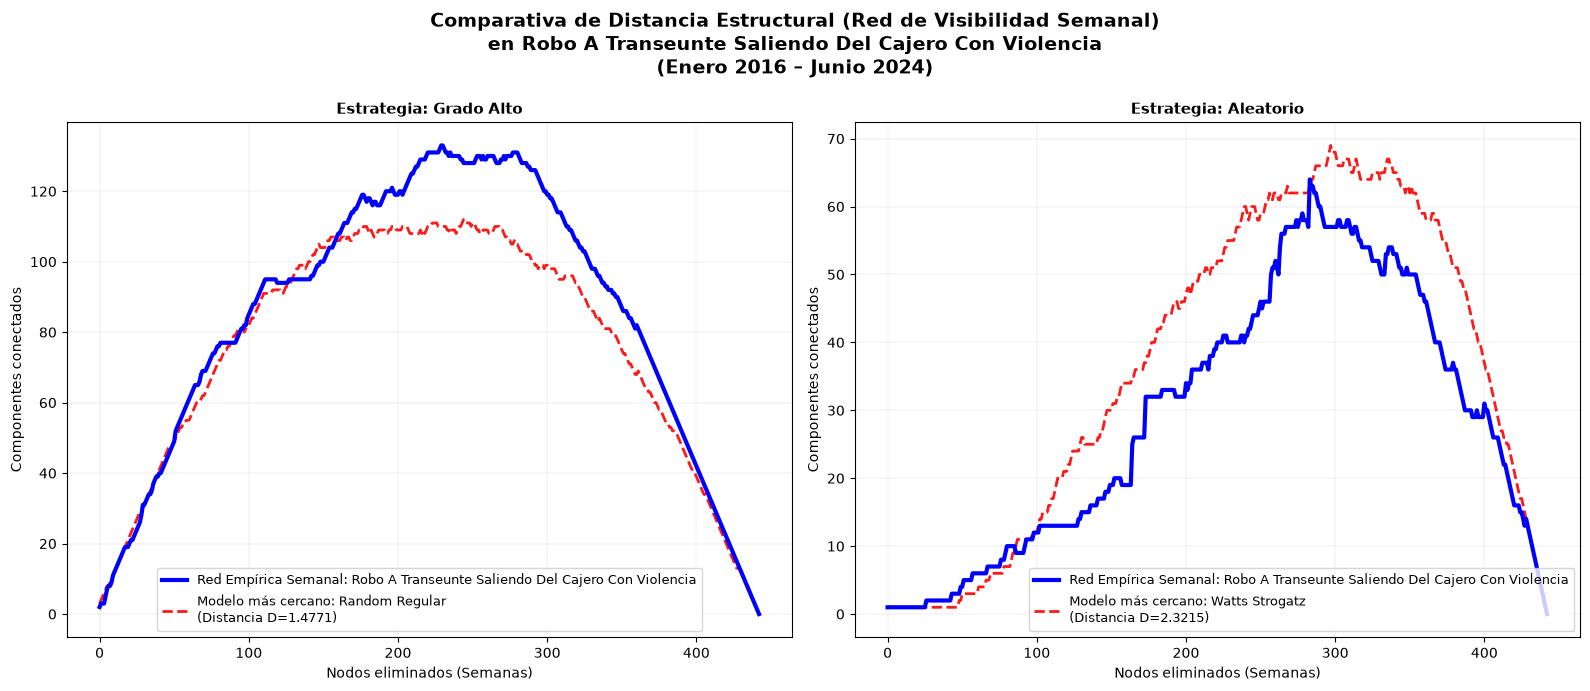

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx
import re

# ======================================================================================
# 1. CONFIGURACIÓN Y CAPTURA DE TEXTOS DINÁMICOS (ANÁLISIS SEMANAL)
# ======================================================================================
meses_es = {
    'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo', 'April': 'Abril',
    'May': 'Mayo', 'June': 'Junio', 'July': 'Julio', 'August': 'Agosto',
    'September': 'Septiembre', 'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'
}

# Captura dinámica del nombre del delito
if 'df_resultados_filtrado' in locals() and not df_resultados_filtrado.empty:
    nombre_delito = df_resultados_filtrado['delito'].iloc[0]
elif 'delito' in locals() and delito:
    nombre_delito = str(delito)
elif 'df_resultados' in locals() and df_resultados is not None and not df_resultados.empty:
    nombre_delito = df_resultados['delito'].iloc[0]
else:
    nombre_delito = "Análisis de Incidencia Semanal"

nombre_delito_formateado = nombre_delito.title()

# Captura dinámica del periodo semanal a partir del grafo o DataFrame
if 'grafo' in locals() and isinstance(grafo, nx.Graph) and nx.get_node_attributes(grafo, 'fecha'):
    fechas_nodos = nx.get_node_attributes(grafo, 'fecha')
    f_min = min(fechas_nodos.values())
    f_max = max(fechas_nodos.values())
    if not isinstance(f_min, pd.Timestamp): f_min = pd.Timestamp(f_min)
    if not isinstance(f_max, pd.Timestamp): f_max = pd.Timestamp(f_max)
    mes_min = meses_es.get(f_min.strftime('%B'), f_min.strftime('%B'))
    mes_max = meses_es.get(f_max.strftime('%B'), f_max.strftime('%B'))
    periodo_txt = f"({mes_min} {f_min.year} – {mes_max} {f_max.year})"
elif 'conteo_semanal' in locals() and not conteo_semanal.empty:
    f_min = conteo_semanal['fecha_hecho'].min()
    f_max = conteo_semanal['fecha_hecho'].max()
    mes_min = meses_es.get(f_min.strftime('%B'), f_min.strftime('%B'))
    mes_max = meses_es.get(f_max.strftime('%B'), f_max.strftime('%B'))
    periodo_txt = f"({mes_min} {f_min.year} – {mes_max} {f_max.year})"
elif 'rango_titulo' in locals():
    periodo_txt = rango_titulo
else:
    periodo_txt = "(Análisis Semanal)"

# ======================================================================================
# 2. GENERACIÓN DE LA GRÁFICA COMPARATIVA
# ======================================================================================
if 'graphs' in locals() and graphs:
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=100)
    axes = axes.flatten()

    nombres_redes = list(graphs.keys())
    G_base_nombre = nombres_redes[0]
    G_base = graphs[G_base_nombre]

    resultados_impresion = []

    for idx, (nombre_estrategia, (ordenador, modo)) in enumerate(estrategias.items()):
        curva_base = curva_renormalizada(G_base, ordenador, modo)
        distancias = []

        for nombre, G in graphs.items():
            if nombre == G_base_nombre or G is None:
                continue
            curva = curva_renormalizada(G, ordenador, modo)
            d = distancia_normalizada(curva_base, curva)
            distancias.append((nombre, curva, d))

        # Obtenemos el modelo más cercano
        distancias = sorted(distancias, key=lambda x: x[2])[:1]
        mejor_nombre, mejor_curva, mejor_d = distancias[0]

        # Guardamos los resultados para la tabla de consola
        resultados_impresion.append({
            'Estrategia': nombre_estrategia,
            'Modelo': mejor_nombre,
            'Distancia': mejor_d
        })

        ax = axes[idx]

        # LÍNEA AZUL: Red Empírica Semanal
        ax.plot(curva_base, label=f"Red Empírica Semanal: {nombre_delito_formateado}",
                linewidth=3, color="blue", zorder=3)

        # LÍNEA ROJA PUNTEADA: Modelo teóricamente más cercano
        ax.plot(mejor_curva, label=f"Modelo más cercano: {mejor_nombre.split('(')[0].strip()}\n(Distancia D={mejor_d:.4f})",
                alpha=0.9, linestyle='--', color="red", linewidth=2, zorder=2)

        ax.set_title(f"Estrategia: {nombre_estrategia.title()}", fontsize=11, fontweight='bold')
        ax.set_xlabel("Nodos eliminados (Semanas)", fontsize=10)
        ax.set_ylabel("Componentes conectados", fontsize=10)
        ax.legend(fontsize=9, loc='best')
        ax.grid(True, linewidth=0.3, linestyle='-', alpha=0.5)

    # ======================================================================================
    # 3. TÍTULO DINÁMICO
    # ======================================================================================
    plt.suptitle(
        f"Comparativa de Distancia Estructural (Red de Visibilidad Semanal)\n"
        f"en {nombre_delito_formateado}\n"
        f"{periodo_txt}",
        fontsize=14, y=0.98, fontweight='bold'
    )

    plt.tight_layout()
    plt.subplots_adjust(top=0.82)

    # ======================================================================================
    # 4. IMPRESIÓN DE TABLA EN CONSOLA
    # ======================================================================================
    print("\n" + "="*70)
    print(f"VALORES ESTRUCTURALES Y PARÁMETROS SEMANALES: {nombre_delito_formateado.upper()}")
    print("="*70)

    for res in resultados_impresion:
        modelo_nombre = res['Modelo']

        # Extracción de k y p del nombre del modelo
        k_match = re.search(r'[kK]=(\d+)', modelo_nombre)
        p_match = re.search(r'[pP]=([\d\.]+)', modelo_nombre)

        k_val = k_match.group(1) if k_match else "N/A"
        p_val = p_match.group(1) if p_match else "N/A"

        print(f"Estrategia       : {res['Estrategia']}")
        print(f"Modelo Cercano   : {modelo_nombre}")
        print(f"Distancia (D)    : {res['Distancia']:.4f}")
        print(f"Parámetros extra : k = {k_val} | p = {p_val}")
        print("-" * 70)

    plt.show()

else:
    print("❌ Error: No se encontró el diccionario 'graphs' con las redes semanales.")